In [1]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install xgboost

In [3]:
!pip show xgboost

Name: xgboost
Version: 1.6.2
Summary: XGBoost Python Package
Home-page: https://github.com/dmlc/xgboost
Author: 
Author-email: 
License: Apache-2.0
Location: C:\Users\amare\anaconda3\Lib\site-packages
Requires: numpy, scipy
Required-by: autoviz


In [4]:
import sys
print(sys.executable)

C:\Users\amare\anaconda3\envs\tensorflow_env\python.exe


In [5]:
!{sys.executable} -m pip install xgboost

In [6]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Mathematical calculation
from math import radians, sin, cos, sqrt, atan2

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# XGBoost
from xgboost import XGBClassifier, XGBRegressor

# Classification Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    auc
)

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

# Regression Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model Saving
import joblib

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Plot style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [7]:
# LOAD THE DATA SET


# Change the path if your CSV is stored somewhere else

#DATA_PATH = r"/mnt/data/b96cfa9e-85f5-40f9-a843-d9237ccdd06b.csv"

df = pd.read_csv("blood_data.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)


Dataset loaded successfully.
Shape: (10000, 41)


In [8]:
# BASIC DATASET INSPECTION


print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Rows: 10000
Columns: 41

Column Names:
['donor_id', 'age', 'gender', 'blood_group', 'donation_count', 'last_donation_days', 'eligible', 'available', 'request_id', 'required_blood_group', 'units_required', 'urgency', 'request_time', 'time_of_day', 'donor_latitude', 'donor_longitude', 'hospital_latitude', 'hospital_longitude', 'distance_km', 'response_history', 'accepted_request', 'travel_time_min', 'compatibility', 'distance_score', 'eta_score', 'match_score', 'donor_rank', 'matched', 'match_status', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40']

First 5 Rows:


,donor_id,age,gender,blood_group,donation_count,last_donation_days,eligible,available,request_id,required_blood_group,...,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40
0,93246afe6c,18,Female,O-,35,179,1,0,1001,O+,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1b8b4c828a,27,Male,A+,31,24,0,0,1001,O+,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,a6a3f7fe55,45,Male,AB-,8,295,1,1,1001,O+,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cee6478144,54,Male,AB+,6,294,1,1,1001,O+,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5986bc55f9,27,Female,A-,20,43,0,0,1001,O+,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Remove unwanted Unnamed columns

unnamed_columns = [
    col for col in df.columns
    if col.startswith("Unnamed:")
]

print("Unwanted columns found:")
print(unnamed_columns)

df = df.drop(
    columns=unnamed_columns,
    errors="ignore"
)

print("\nDataset shape after removing Unnamed columns:")
print(df.shape)

print("\nFinal columns:")
print(df.columns.tolist())

Unwanted columns found:
['Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40']

Dataset shape after removing Unnamed columns:
(10000, 29)

Final columns:
['donor_id', 'age', 'gender', 'blood_group', 'donation_count', 'last_donation_days', 'eligible', 'available', 'request_id', 'required_blood_group', 'units_required', 'urgency', 'request_time', 'time_of_day', 'donor_latitude', 'donor_longitude', 'hospital_latitude', 'hospital_longitude', 'distance_km', 'response_history', 'accepted_request', 'travel_time_min', 'compatibility', 'distance_score', 'eta_score', 'match_score', 'donor_rank', 'matched', 'match_status']


In [10]:
#Dataset Information

print("Dataset Information:\n")

df.info()

Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   donor_id              10000 non-null  str    
 1   age                   10000 non-null  int64  
 2   gender                10000 non-null  str    
 3   blood_group           10000 non-null  str    
 4   donation_count        10000 non-null  int64  
 5   last_donation_days    10000 non-null  int64  
 6   eligible              10000 non-null  int64  
 7   available             10000 non-null  int64  
 8   request_id            10000 non-null  int64  
 9   required_blood_group  10000 non-null  str    
 10  units_required        10000 non-null  int64  
 11  urgency               10000 non-null  str    
 12  request_time          10000 non-null  str    
 13  time_of_day           10000 non-null  str    
 14  donor_latitude        10000 non-null  float64
 15  donor_lon

In [11]:
#Statistical Summary

display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
donor_id,10000,10000,93246afe6c,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,41.2181,13.837134,18.0,29.0,41.0,53.0,65.0
gender,10000,2,Male,6087,NaN,NaN,NaN,NaN,NaN,NaN,NaN
blood_group,10000,8,B-,1290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
donation_count,10000.0,NaN,NaN,NaN,25.1282,14.654195,0.0,12.0,26.0,38.0,50.0
last_donation_days,10000.0,NaN,NaN,NaN,155.9594,73.549041,1.0,105.0,155.5,206.0,365.0
eligible,10000.0,NaN,NaN,NaN,0.9095,0.286911,0.0,1.0,1.0,1.0,1.0
available,10000.0,NaN,NaN,NaN,0.5085,0.499953,0.0,0.0,1.0,1.0,1.0
request_id,10000.0,NaN,NaN,NaN,1500.5,288.689425,1001.0,1250.75,1500.5,1750.25,2000.0
required_blood_group,10000,8,A+,2900,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# missing values

missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing_values.index,
    "Missing_Values": missing_values.values
})

missing_table = missing_table.sort_values(
    by="Missing_Values",
    ascending=False
)

display(missing_table)

,Column,Missing_Values
0,donor_id,0
1,age,0
2,gender,0
3,blood_group,0
4,donation_count,0
5,last_donation_days,0
6,eligible,0
7,available,0
8,request_id,0
9,required_blood_group,0


In [13]:
#Handle Missing Values

# Separate numerical and categorical columns

numeric_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include="object"
).columns

# Fill numerical missing values with median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled.")

print("\nTotal remaining missing values:")
print(df.isnull().sum().sum())

Missing values handled.

Total remaining missing values:
0


In [14]:
# duplicates removal

duplicate_count = df.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)

Duplicate rows before removal: 0
Shape after duplicate removal: (10000, 29)


In [15]:
# data type checking

dtype_table = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

display(dtype_table)

,Column,Data_Type
0,donor_id,str
1,age,int64
2,gender,str
3,blood_group,str
4,donation_count,int64
5,last_donation_days,int64
6,eligible,int64
7,available,int64
8,request_id,int64
9,required_blood_group,str


In [16]:
# convert request time

df["request_time"] = pd.to_datetime(
    df["request_time"],
    errors="coerce"
)

print(df["request_time"].dtype)

datetime64[us]


In [17]:
# haversine distance calculations

def haversine_distance(
    lat1,
    lon1,
    lat2,
    lon2
):
    """
    Calculate distance between two geographic coordinates
    using the Haversine formula.
    """

    R = 6371.0  # Earth radius in kilometers

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        +
        np.cos(lat1)
        *
        np.cos(lat2)
        *
        np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arctan2(
        np.sqrt(a),
        np.sqrt(1 - a)
    )

    return R * c


print("Haversine function created.")

Haversine function created.


In [18]:
# calculate distance

df["distance_km_calculated"] = haversine_distance(
    df["donor_latitude"],
    df["donor_longitude"],
    df["hospital_latitude"],
    df["hospital_longitude"]
)

df["distance_km_calculated"] = df[
    "distance_km_calculated"
].round(2)

display(
    df[
        [
            "distance_km",
            "distance_km_calculated"
        ]
    ].head(10)
)

,distance_km,distance_km_calculated
0,12.59,12.59
1,10.97,10.97
2,27.42,27.42
3,13.75,13.75
4,12.24,12.24
5,16.40,16.40
6,9.97,9.97
7,10.19,10.19
8,6.52,6.52
9,0.36,0.36


In [19]:
# use calculated distance

# Replace original distance with mathematically calculated distance

df["distance_km"] = df["distance_km_calculated"]

df.drop(
    columns=["distance_km_calculated"],
    inplace=True
)

print("Distance calculation completed.")

display(df[[
    "donor_latitude",
    "donor_longitude",
    "hospital_latitude",
    "hospital_longitude",
    "distance_km"
]].head())

Distance calculation completed.


,donor_latitude,donor_longitude,hospital_latitude,hospital_longitude,distance_km
0,-12.357872,130.938935,-12.4307,130.8502,12.59
1,-42.845534,147.202402,-42.8826,147.3272,10.97
2,-12.350532,130.611476,-12.4307,130.8502,27.42
3,-37.969862,144.978441,-37.9184,145.1210,13.75
4,-12.465416,130.743235,-12.4307,130.8502,12.24


In [20]:
# Travel time calculations

# Assume average emergency/local travel speed = 30 km/hour
AVERAGE_SPEED_KMPH = 30

df["travel_time_min_calculated"] = (
    df["distance_km"] / AVERAGE_SPEED_KMPH
) * 60

df["travel_time_min_calculated"] = (
    df["travel_time_min_calculated"]
    .clip(lower=5)
    .round()
    .astype(int)
)

# Replace original travel time with calculated travel time
df["travel_time_min"] = df["travel_time_min_calculated"]

# Remove temporary column
df.drop(
    columns=["travel_time_min_calculated"],
    inplace=True
)

print("Travel time calculation completed.")

display(
    df[
        [
            "distance_km",
            "travel_time_min"
        ]
    ].head(10)
)

Travel time calculation completed.


,distance_km,travel_time_min
0,12.59,25
1,10.97,22
2,27.42,55
3,13.75,28
4,12.24,24
5,16.40,33
6,9.97,20
7,10.19,20
8,6.52,13
9,0.36,5


In [21]:
# Finalize travel time

print("Travel time calculation completed.")

print(
    df["travel_time_min"].describe()
)

Travel time calculation completed.
count    10000.000000
mean        34.227200
std         18.626118
min          5.000000
25%         20.000000
50%         32.000000
75%         46.000000
max        123.000000
Name: travel_time_min, dtype: float64


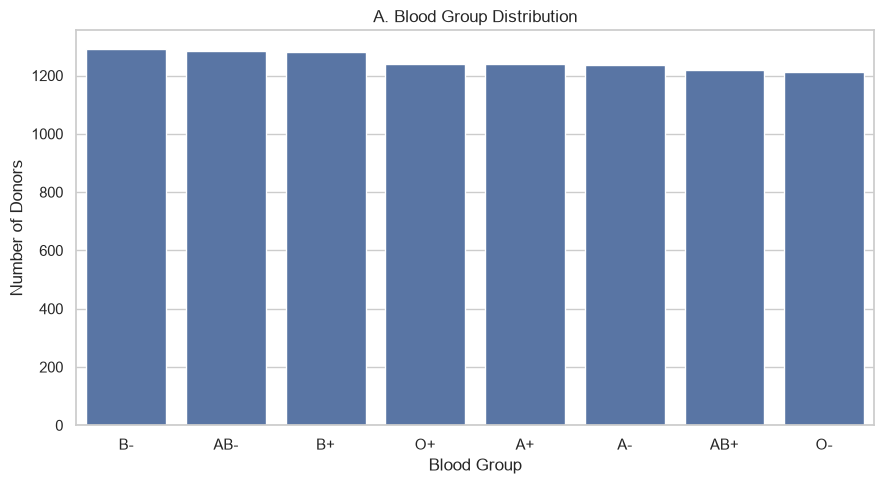

In [22]:
# EDA -- BLOOD GROUP DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="blood_group",
    order=df["blood_group"].value_counts().index
)

plt.title("A. Blood Group Distribution")
plt.xlabel("Blood Group")
plt.ylabel("Number of Donors")

plt.tight_layout()
plt.show()

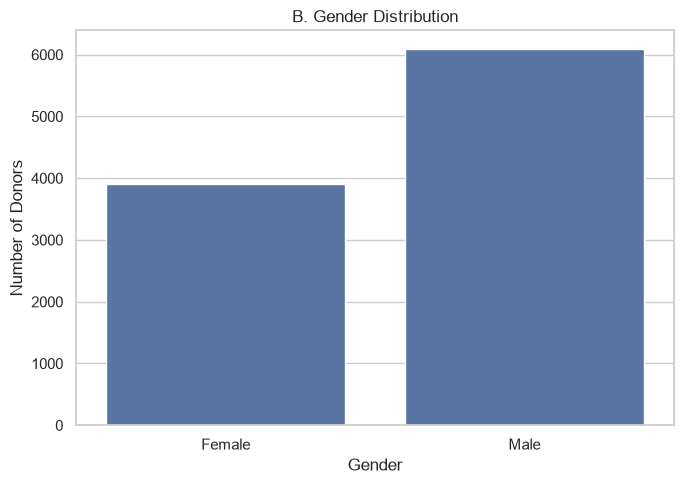

In [23]:
# EDA-- GENDER DISTRIBUTION

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="gender"
)

plt.title("B. Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Donors")

plt.tight_layout()
plt.show()

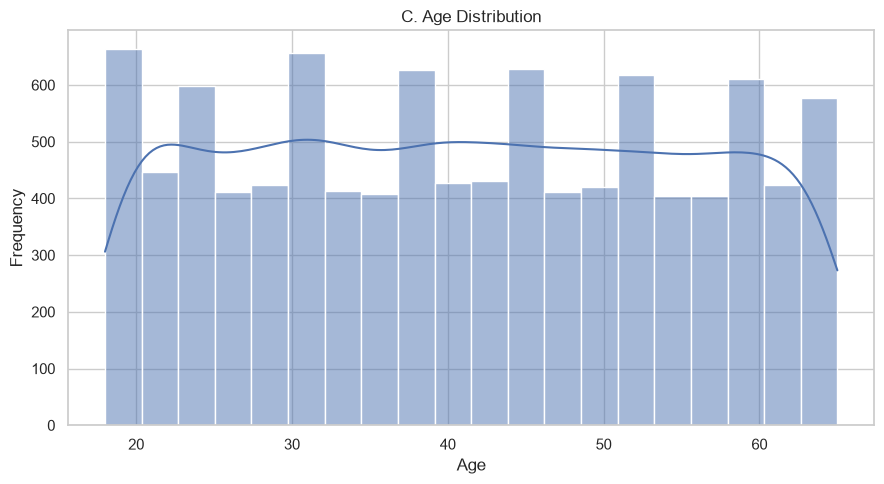

In [24]:
# EDA-- AGE DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("C. Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

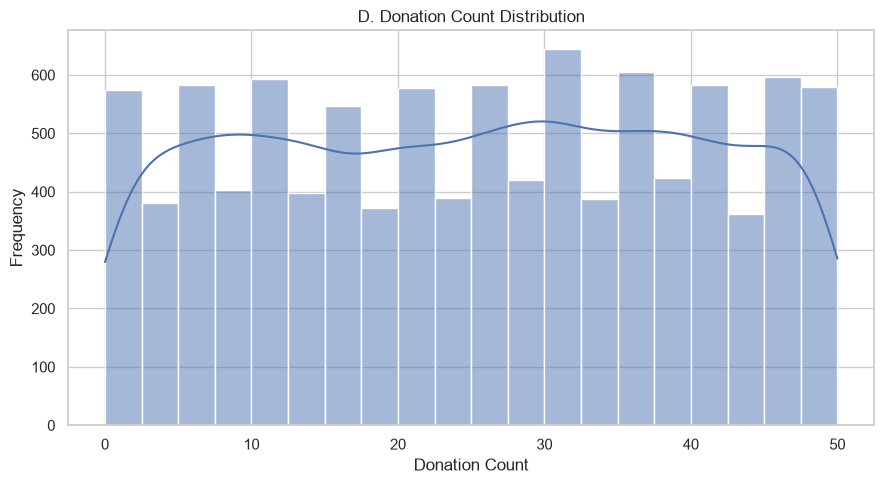

In [25]:
# EDA-- DONATION COUNT DISTRIBUTION
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="donation_count",
    bins=20,
    kde=True
)

plt.title("D. Donation Count Distribution")
plt.xlabel("Donation Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

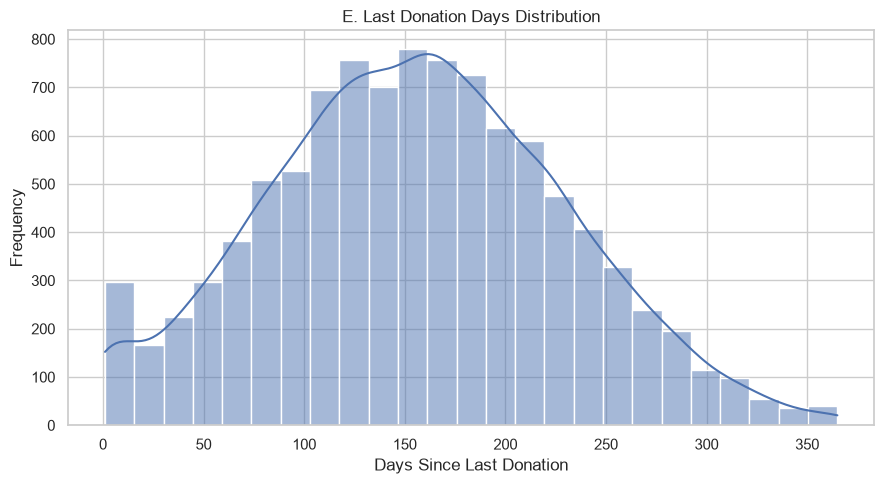

In [26]:
# EDA-- LAST DONATION DATE

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="last_donation_days",
    bins=25,
    kde=True
)

plt.title("E. Last Donation Days Distribution")
plt.xlabel("Days Since Last Donation")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

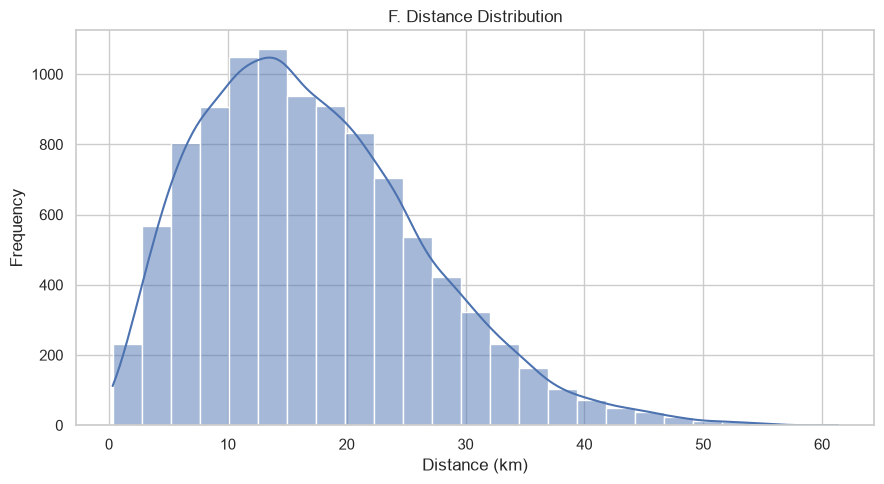

In [27]:
# EDA -- DISTANCE DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="distance_km",
    bins=25,
    kde=True
)

plt.title("F. Distance Distribution")
plt.xlabel("Distance (km)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

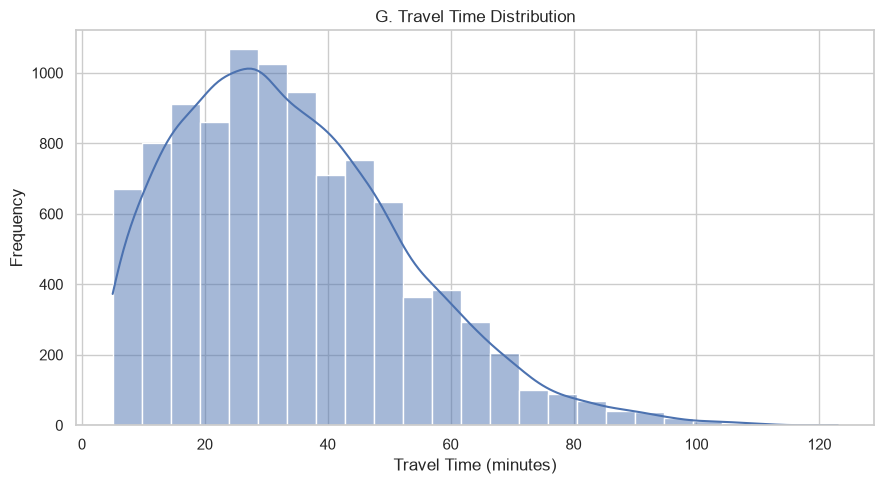

In [28]:
# EDA -- TRAVEL TIME DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="travel_time_min",
    bins=25,
    kde=True
)

plt.title("G. Travel Time Distribution")
plt.xlabel("Travel Time (minutes)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

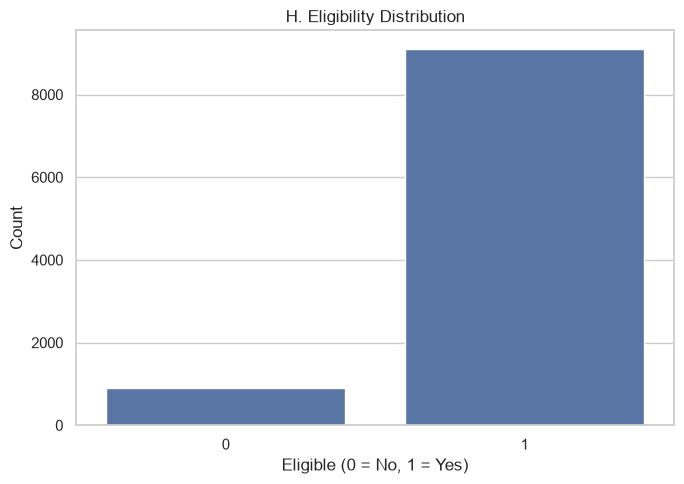

In [29]:
# EDA-- ELIGIBILITY DISTRIBUTION

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="eligible"
)

plt.title("H. Eligibility Distribution")
plt.xlabel("Eligible (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

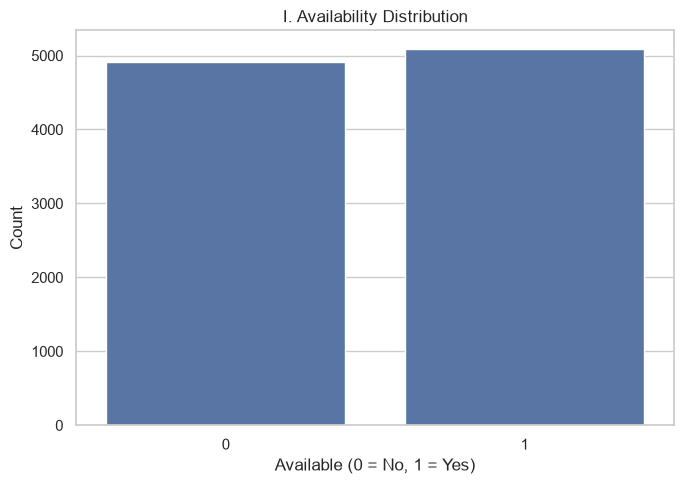

In [30]:
# EDA -- AVALABILITY DISTRIBUTION

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="available"
)

plt.title("I. Availability Distribution")
plt.xlabel("Available (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

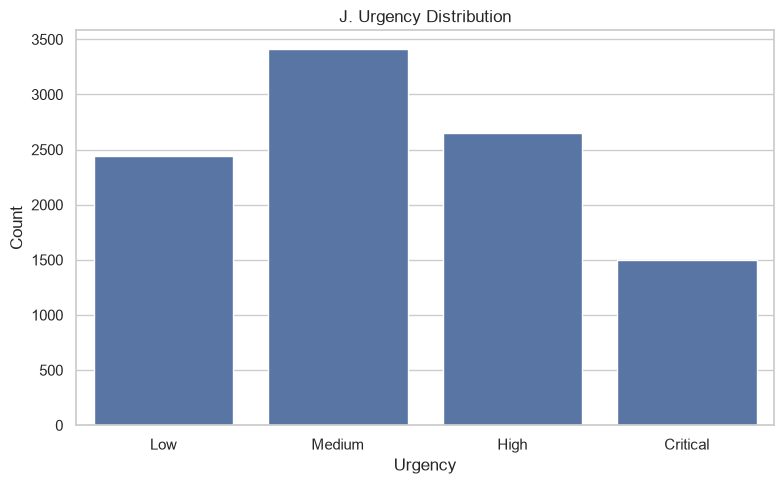

In [31]:
# EDA -- URGENCY DISTRIBUTION

plt.figure(figsize=(8, 5))

order = ["Low", "Medium", "High", "Critical"]

sns.countplot(
    data=df,
    x="urgency",
    order=[
        x for x in order
        if x in df["urgency"].unique()
    ]
)

plt.title("J. Urgency Distribution")
plt.xlabel("Urgency")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

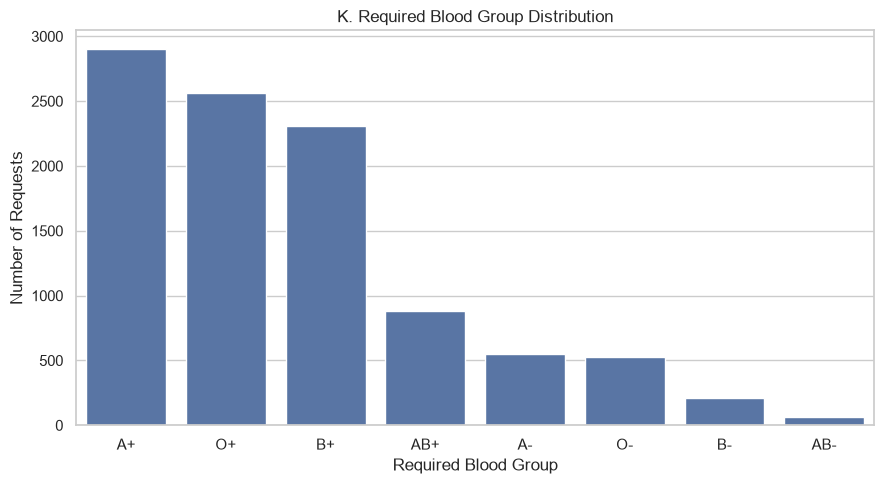

In [32]:
# EDA -- REQUIRED BLODD GROUP

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="required_blood_group",
    order=df[
        "required_blood_group"
    ].value_counts().index
)

plt.title("K. Required Blood Group Distribution")
plt.xlabel("Required Blood Group")
plt.ylabel("Number of Requests")

plt.tight_layout()
plt.show()

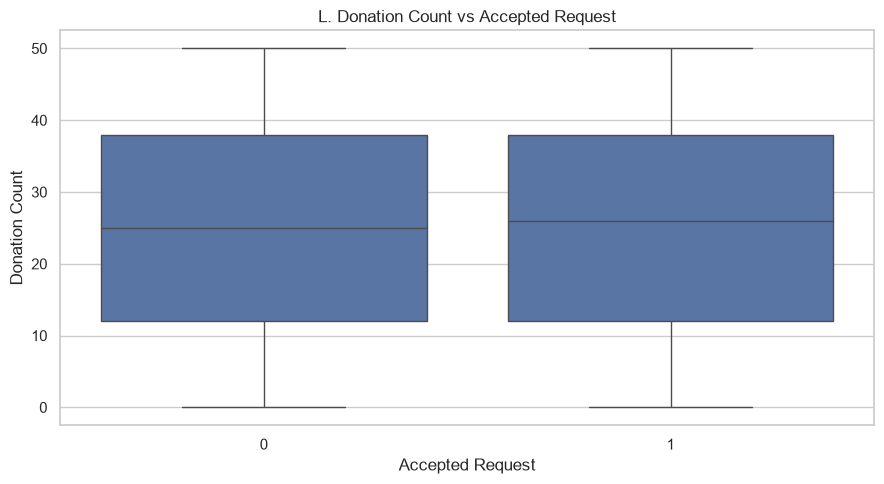

In [33]:
# DONATION COUNT VS ACCEPTED REQUEST

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="accepted_request",
    y="donation_count"
)

plt.title("L. Donation Count vs Accepted Request")
plt.xlabel("Accepted Request")
plt.ylabel("Donation Count")

plt.tight_layout()
plt.show()

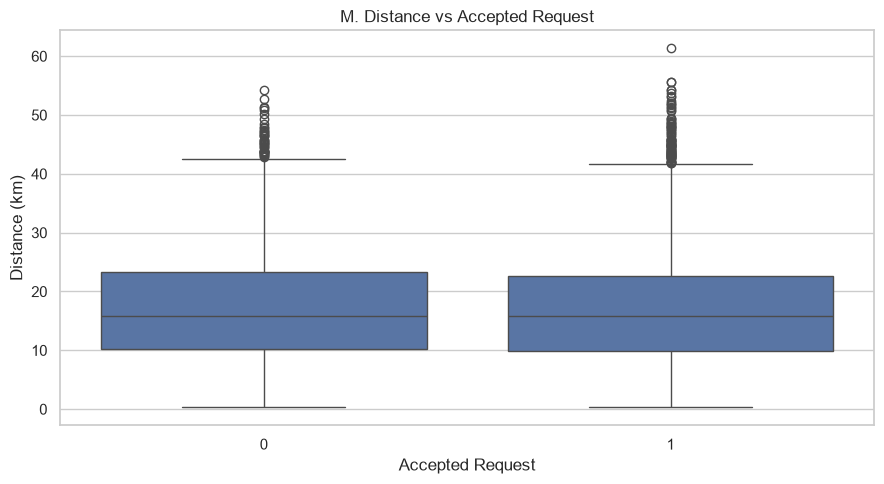

In [34]:
# DISTANCE VS ACCEPTED REQUEST

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="accepted_request",
    y="distance_km"
)

plt.title("M. Distance vs Accepted Request")
plt.xlabel("Accepted Request")
plt.ylabel("Distance (km)")

plt.tight_layout()
plt.show()

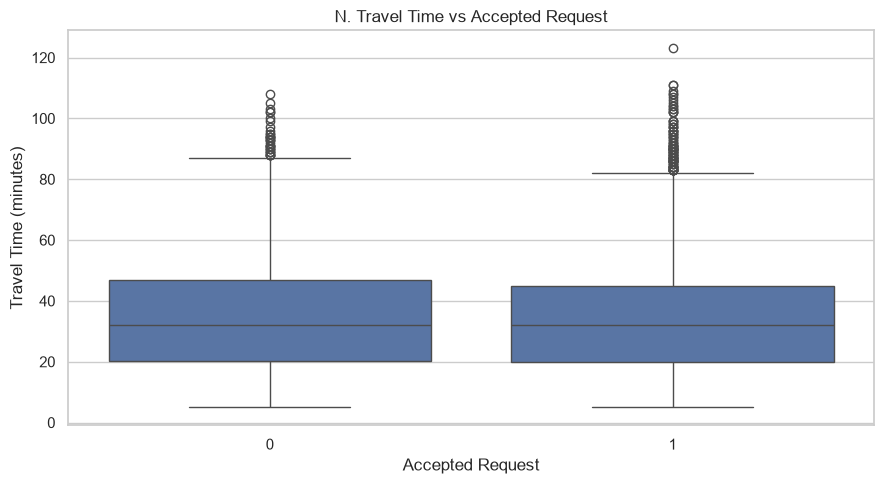

In [35]:
#TRAVEL TIME VS ACCEPTED REQUEST

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="accepted_request",
    y="travel_time_min"
)

plt.title("N. Travel Time vs Accepted Request")
plt.xlabel("Accepted Request")
plt.ylabel("Travel Time (minutes)")

plt.tight_layout()
plt.show()

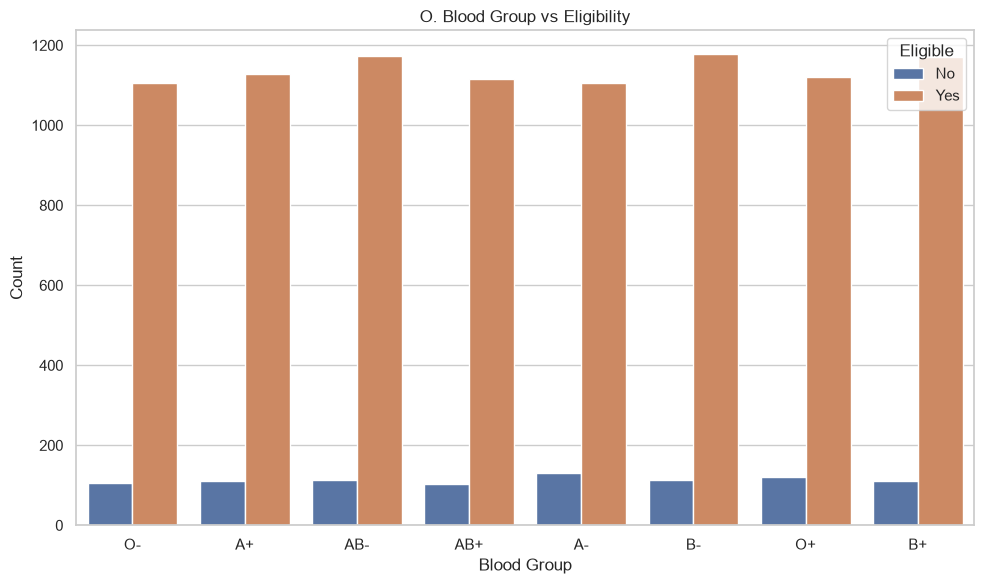

In [36]:
# BLOOD GROUP VS ELIGIBILITY

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="blood_group",
    hue="eligible"
)

plt.title("O. Blood Group vs Eligibility")
plt.xlabel("Blood Group")
plt.ylabel("Count")

plt.legend(
    title="Eligible",
    labels=["No", "Yes"]
)

plt.tight_layout()
plt.show()

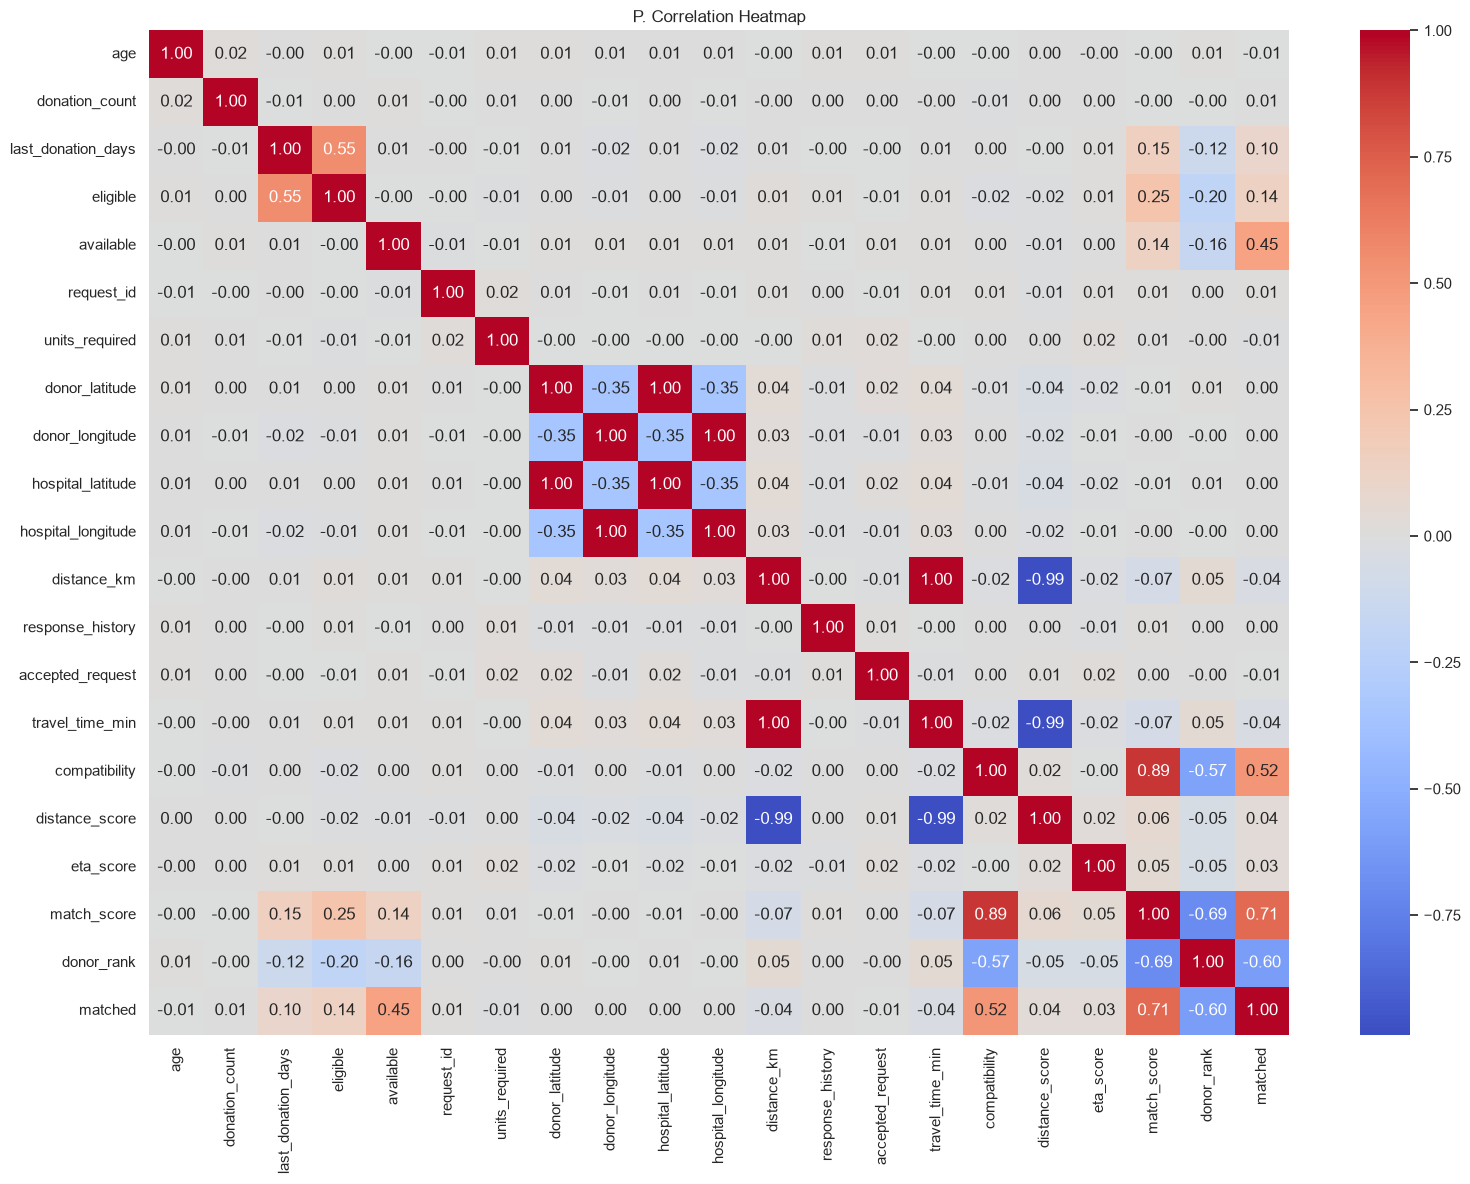

In [37]:
#CORELATION HEATMAP

numeric_df = df.select_dtypes(
    include=np.number
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("P. Correlation Heatmap")

plt.tight_layout()
plt.show()

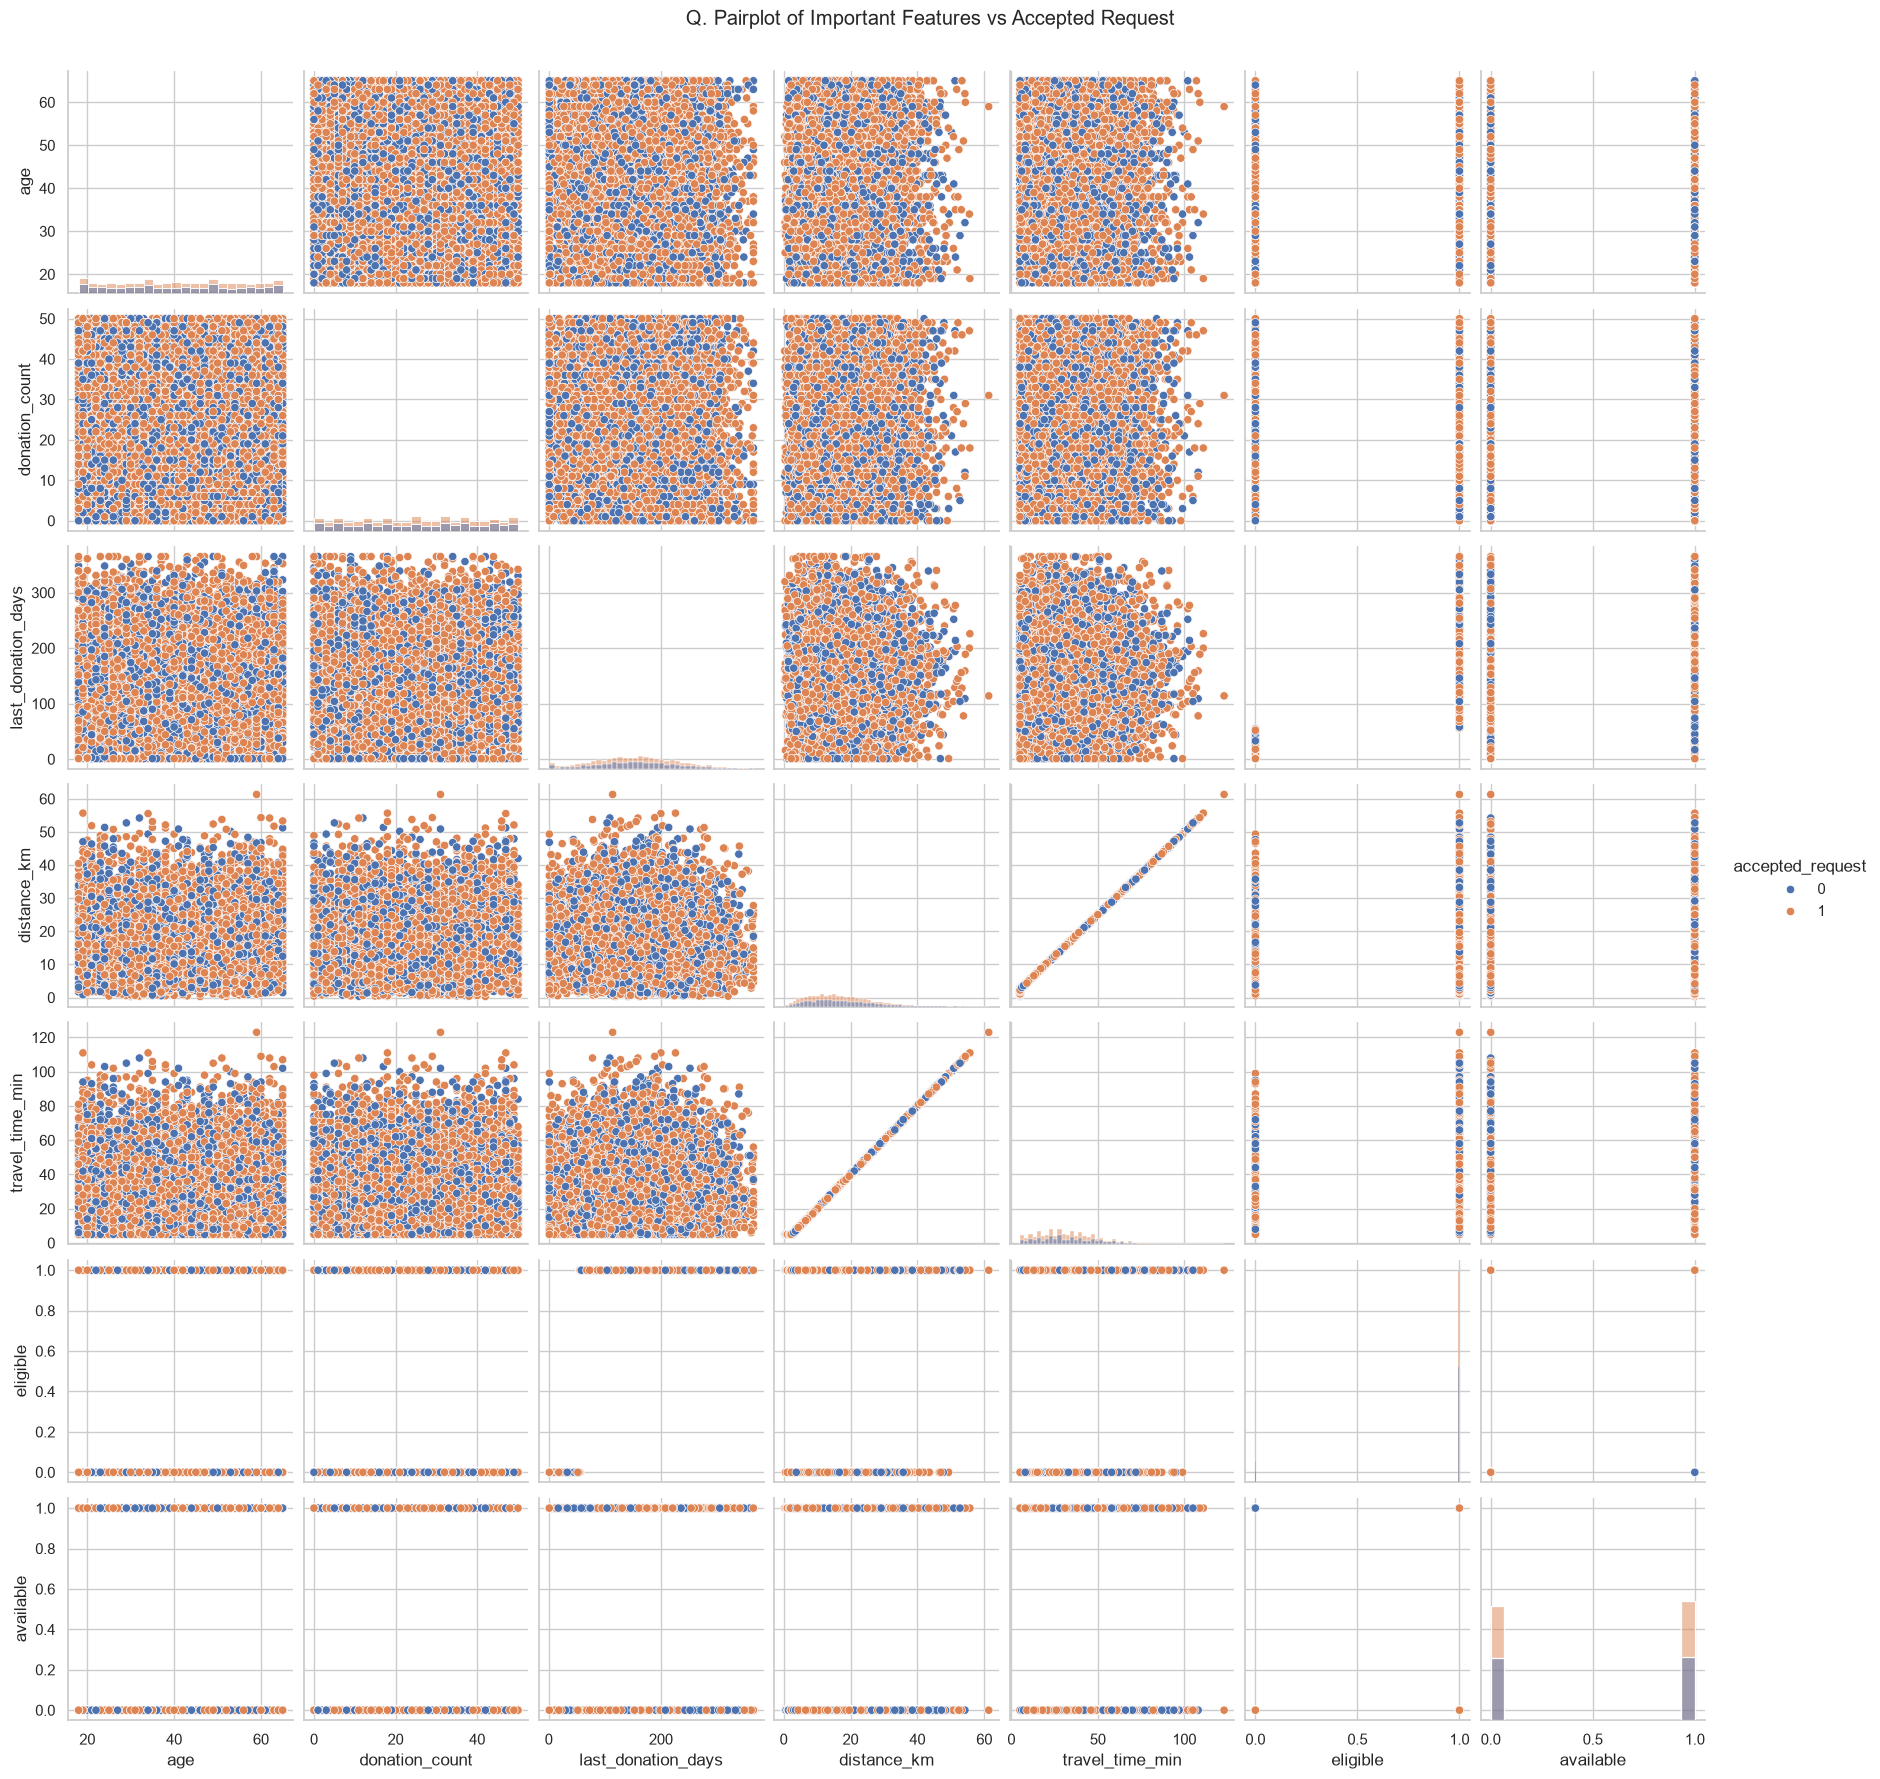

In [38]:
important_features = [
    "age",
    "donation_count",
    "last_donation_days",
    "distance_km",
    "travel_time_min",
    "eligible",
    "available",
    "accepted_request"
]

sns.pairplot(
    df[important_features],
    hue="accepted_request",
    diag_kind="hist"
)

plt.suptitle(
    "Q. Pairplot of Important Features vs Accepted Request",
    y=1.02
)

plt.show()

In [39]:
# blood compatibility logic
# RBC BLOOD COMPATIBILITY LOGIC

blood_compatibility = {
    "O-":  ["O-"],
    "O+":  ["O-", "O+"],
    "A-":  ["O-", "A-"],
    "A+":  ["O-", "O+", "A-", "A+"],
    "B-":  ["O-", "B-"],
    "B+":  ["O-", "O+", "B-", "B+"],
    "AB-": ["O-", "A-", "B-", "AB-"],
    "AB+": ["O-", "O+", "A-", "A+", "B-", "B+", "AB-", "AB+"]
}

def check_compatibility(
    donor_group,
    required_group
):
    compatible_donors = blood_compatibility.get(
        required_group,
        []
    )

    return int(
        donor_group in compatible_donors
    )

print("Blood compatibility function created.")

Blood compatibility function created.


In [40]:
# CALCULATE COMPATIBILITY FEATURE
df["compatibility"] = df.apply(
    lambda row: check_compatibility(
        row["blood_group"],
        row["required_blood_group"]
    ),
    axis=1
)

print(
    df["compatibility"].value_counts()
)

compatibility
0    5600
1    4400
Name: count, dtype: int64


In [41]:
#Feature Engineering: Donation Frequency

# Approximate donation frequency
# Higher value means more frequent donation activity

df["donation_frequency"] = (
    df["donation_count"]
    /
    ((df["last_donation_days"] + 1) / 30)
)

df["donation_frequency"] = (
    df["donation_frequency"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

df["donation_frequency"] = (
    df["donation_frequency"]
    .round(2)
)

display(
    df[
        [
            "donation_count",
            "last_donation_days",
            "donation_frequency"
        ]
    ].head(10)
)

,donation_count,last_donation_days,donation_frequency
0,35,179,5.83
1,31,24,37.20
2,8,295,0.81
3,6,294,0.61
4,20,43,13.64
5,21,132,4.74
6,9,108,2.48
7,19,215,2.64
8,5,145,1.03
9,11,141,2.32


In [42]:
# distance score

# Smaller distance = higher score

max_distance = df["distance_km"].max()

df["distance_score"] = (
    1 -
    (
        df["distance_km"]
        /
        max_distance
    )
).clip(0, 1)

df["distance_score"] = (
    df["distance_score"]
    .round(3)
)

display(
    df[
        [
            "distance_km",
            "distance_score"
        ]
    ].head(10)
)

,distance_km,distance_score
0,12.59,0.795
1,10.97,0.821
2,27.42,0.553
3,13.75,0.776
4,12.24,0.800
5,16.40,0.733
6,9.97,0.837
7,10.19,0.834
8,6.52,0.894
9,0.36,0.994


In [43]:
# ETA SCORE

# Smaller travel time = higher ETA score

max_travel_time = df["travel_time_min"].max()

if max_travel_time > 0:
    df["eta_score"] = (
        1 -
        (
            df["travel_time_min"]
            /
            max_travel_time
        )
    ).clip(0, 1)
else:
    df["eta_score"] = 1.0

df["eta_score"] = (
    df["eta_score"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
    .round(3)
)

display(
    df[
        [
            "travel_time_min",
            "eta_score"
        ]
    ].head(10)
)

,travel_time_min,eta_score
0,25,0.797
1,22,0.821
2,55,0.553
3,28,0.772
4,24,0.805
5,33,0.732
6,20,0.837
7,20,0.837
8,13,0.894
9,5,0.959


In [44]:
# ============================================
# FEATURE ENGINEERING SUMMARY
# ============================================

feature_columns = [
    "age",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "units_required",
    "response_history",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "donation_frequency"
]

display(
    df[feature_columns].head()
)

print("\nTotal ML feature columns:", len(feature_columns))
print("\nFeature columns:")
print(feature_columns)

,age,donation_count,last_donation_days,eligible,available,units_required,response_history,distance_km,travel_time_min,compatibility,donation_frequency
0,18,35,179,1,0,1,0,12.59,25,1,5.83
1,27,31,24,0,0,1,7,10.97,22,0,37.20
2,45,8,295,1,1,1,9,27.42,55,0,0.81
3,54,6,294,1,1,1,9,13.75,28,0,0.61
4,27,20,43,0,0,1,9,12.24,24,0,13.64



Total ML feature columns: 11

Feature columns:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'response_history', 'distance_km', 'travel_time_min', 'compatibility', 'donation_frequency']


In [45]:
# ============================================
# Cell 40 — Prepare Classification Dataset
# ============================================

# --------------------------------------------
# Classification Target
# --------------------------------------------
# 0 = Donor did not accept/respond positively
# 1 = Donor accepted/responded positively

y_class =  df["matched"].astype(int)

# --------------------------------------------
# Classification Features
# --------------------------------------------

classification_features = [
    "age",
    "gender",
    "blood_group",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "required_blood_group",
    "units_required",
    "urgency",
    "time_of_day",
    "distance_km",
    "travel_time_min",
    "response_history",
    "compatibility",
    "donation_frequency"
]

# Keep only available columns
available_features = [
    col
    for col in classification_features
    if col in df.columns
]

print("Available Features:")
print(available_features)

# --------------------------------------------
# Create Feature DataFrame
# --------------------------------------------

X_class = df[available_features].copy()

# --------------------------------------------
# Dataset Information
# --------------------------------------------

print("\nClassification Target:")
print("accepted_request")

print("\nX Shape:", X_class.shape)
print("y Shape:", y_class.shape)

print("\nTarget Distribution:")
print(y_class.value_counts())

print("\nTarget Percentage:")
print(
    round(
        y_class.value_counts(normalize=True) * 100,
        2
    )
)

print("\nMissing Values in X:")
print(X_class.isnull().sum().sum())

print("\nFeature Data Types:")
print(X_class.dtypes)

print("\nFeature Preview:")
display(X_class.head())

Available Features:
['age', 'gender', 'blood_group', 'donation_count', 'last_donation_days', 'eligible', 'available', 'required_blood_group', 'units_required', 'urgency', 'time_of_day', 'distance_km', 'travel_time_min', 'response_history', 'compatibility', 'donation_frequency']

Classification Target:
accepted_request

X Shape: (10000, 16)
y Shape: (10000,)

Target Distribution:
matched
0    8272
1    1728
Name: count, dtype: int64

Target Percentage:
matched
0    82.72
1    17.28
Name: proportion, dtype: float64

Missing Values in X:
0

Feature Data Types:
age                       int64
gender                      str
blood_group                 str
donation_count            int64
last_donation_days        int64
eligible                  int64
available                 int64
required_blood_group        str
units_required            int64
urgency                     str
time_of_day                 str
distance_km             float64
travel_time_min           int64
response_history    

,age,gender,blood_group,donation_count,last_donation_days,eligible,available,required_blood_group,units_required,urgency,time_of_day,distance_km,travel_time_min,response_history,compatibility,donation_frequency
0,18,Female,O-,35,179,1,0,O+,1,Medium,Night,12.59,25,0,1,5.83
1,27,Male,A+,31,24,0,0,O+,1,Medium,Night,10.97,22,7,0,37.20
2,45,Male,AB-,8,295,1,1,O+,1,Medium,Night,27.42,55,9,0,0.81
3,54,Male,AB+,6,294,1,1,O+,1,Medium,Night,13.75,28,9,0,0.61
4,27,Female,A-,20,43,0,0,O+,1,Medium,Night,12.24,24,9,0,13.64


In [46]:
# train , test , split for classification

from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training data:", X_train_class.shape)
print("Testing data:", X_test_class.shape)

Training data: (8000, 16)
Testing data: (2000, 16)


In [47]:
# ============================================
# Cell 42 — Classification Preprocessing Setup
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --------------------------------------------
# Identify Numerical and Categorical Features
# --------------------------------------------

categorical_features = [
    "gender",
    "blood_group",
    "required_blood_group",
    "urgency",
    "time_of_day"
]

numerical_features = [
    "age",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "units_required",
    "response_history",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "donation_frequency"
]

# Keep only columns that actually exist
categorical_features = [
    col for col in categorical_features
    if col in X_train_class.columns
]

numerical_features = [
    col for col in numerical_features
    if col in X_train_class.columns
]

# --------------------------------------------
# Numerical Preprocessing
# --------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# --------------------------------------------
# Categorical Preprocessing
# --------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# --------------------------------------------
# Combined Preprocessor
# --------------------------------------------

preprocessor_class = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Classification preprocessing pipeline created.")

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Classification preprocessing pipeline created.

Numerical features:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'response_history', 'distance_km', 'travel_time_min', 'compatibility', 'donation_frequency']

Categorical features:
['gender', 'blood_group', 'required_blood_group', 'urgency', 'time_of_day']


In [48]:
# ============================================
# Cell 43 — Logistic Regression
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

# Train model
logistic_model.fit(
    X_train_class,
    y_train_class
)

# Predictions
logistic_predictions = logistic_model.predict(
    X_test_class
)

# Prediction probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_test_class
)[:, 1]

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [49]:
# ============================================
# Cell 44 — Decision Tree Classifier
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

# Train model
decision_tree_model.fit(
    X_train_class,
    y_train_class
)

# Predictions
dt_predictions = decision_tree_model.predict(
    X_test_class
)

# Prediction probabilities
dt_probabilities = decision_tree_model.predict_proba(
    X_test_class
)[:, 1]

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [50]:
# ============================================
# Cell 45 — Random Forest Classifier
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train model
random_forest_model.fit(
    X_train_class,
    y_train_class
)

# Predictions
rf_predictions = random_forest_model.predict(
    X_test_class
)

# Prediction probabilities
rf_probabilities = random_forest_model.predict_proba(
    X_test_class
)[:, 1]

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [51]:
# ============================================
# Cell 46 — XGBoost Classifier
# ============================================

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

# Train model
xgb_classifier.fit(
    X_train_class,
    y_train_class
)

# Predictions
xgb_predictions = xgb_classifier.predict(
    X_test_class
)

# Prediction probabilities
xgb_probabilities = xgb_classifier.predict_proba(
    X_test_class
)[:, 1]

print("XGBoost Classifier trained successfully.")

XGBoost Classifier trained successfully.


In [52]:
# ============================================
# Cell 47 — KNN Classifier
# ============================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=7
            )
        )
    ]
)

# Train model
knn_model.fit(
    X_train_class,
    y_train_class
)

# Predictions
knn_predictions = knn_model.predict(
    X_test_class
)

# Prediction probabilities
knn_probabilities = knn_model.predict_proba(
    X_test_class
)[:, 1]

print("KNN Classifier trained successfully.")

KNN Classifier trained successfully.


In [53]:
#Classification Evaluation Function

def evaluate_classifier(
    model_name,
    y_true,
    predictions,
    probabilities
):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            probabilities
        )
    }

In [54]:
# ============================================
# Cell 49 — Compare Classification Models
# ============================================

classification_results = []

classification_results.append(
    evaluate_classifier(
        "Logistic Regression",
        y_test_class,
        logistic_predictions,
        logistic_probabilities
    )
)

classification_results.append(
    evaluate_classifier(
        "Decision Tree",
        y_test_class,
        dt_predictions,
        dt_probabilities
    )
)

classification_results.append(
    evaluate_classifier(
        "Random Forest",
        y_test_class,
        rf_predictions,
        rf_probabilities
    )
)

classification_results.append(
    evaluate_classifier(
        "XGBoost",
        y_test_class,
        xgb_predictions,
        xgb_probabilities
    )
)

classification_results.append(
    evaluate_classifier(
        "KNN",
        y_test_class,
        knn_predictions,
        knn_probabilities
    )
)

# Convert results to DataFrame
classification_results_df = pd.DataFrame(
    classification_results
)

# Sort by Accuracy
classification_results_df = (
    classification_results_df
    .sort_values(
        by="Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Classification Model Comparison:")

display(
    classification_results_df.round(4)
)

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9780,0.8932,0.9913,0.9397,0.9942
1,Random Forest,0.9780,0.8995,0.9827,0.9392,0.9928
2,XGBoost,0.9775,0.8992,0.9798,0.9378,0.9937
3,Decision Tree,0.9760,0.9027,0.9653,0.9330,0.9880
4,KNN,0.9695,0.8645,0.9769,0.9172,0.9877


In [55]:
# classification report

best_classifier_name = classification_results_df.iloc[0]["Model"]

prediction_dictionary = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "KNN": knn_predictions
}

best_predictions = prediction_dictionary[
    best_classifier_name
]

print("Best Classification Model:")
print(best_classifier_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_class,
        best_predictions,
        target_names=[
            "Not Matched",
            "Matched"
        ],
        zero_division=0
    )
)

Best Classification Model:
Logistic Regression

Classification Report:

              precision    recall  f1-score   support

 Not Matched       1.00      0.98      0.99      1654
     Matched       0.89      0.99      0.94       346

    accuracy                           0.98      2000
   macro avg       0.95      0.98      0.96      2000
weighted avg       0.98      0.98      0.98      2000



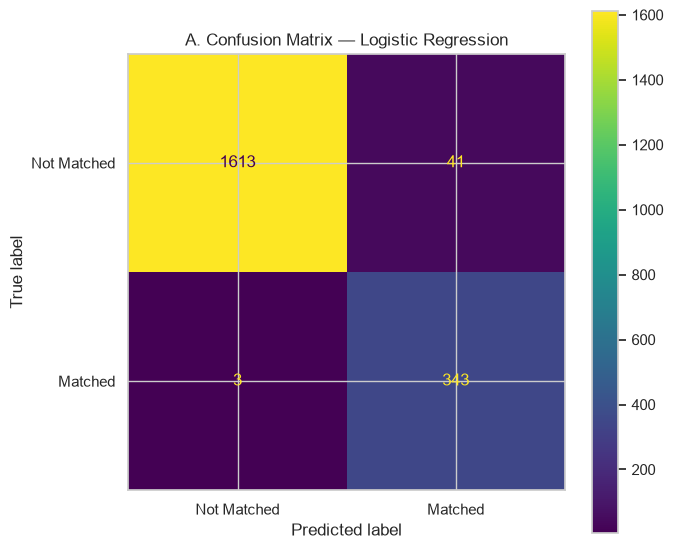

In [56]:
#confusion matrix

cm = confusion_matrix(
    y_test_class,
    best_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Matched",
        "Matched"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    f"A. Confusion Matrix — {best_classifier_name}"
)

plt.tight_layout()
plt.show()

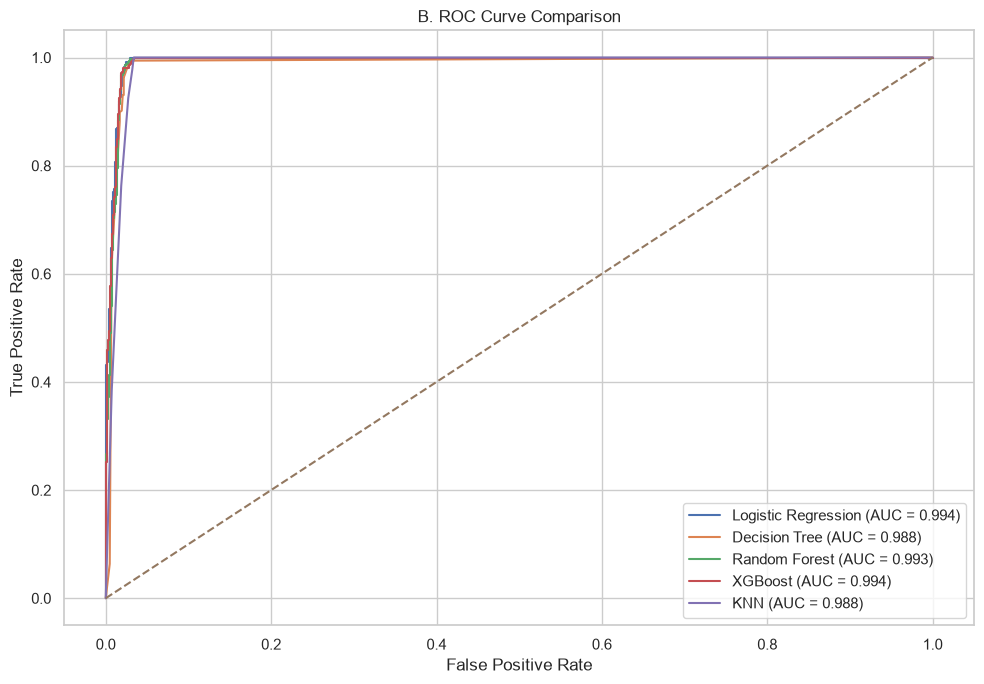

In [57]:
#ROC Curve Comparison

models_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": dt_probabilities,
    "Random Forest": rf_probabilities,
    "XGBoost": xgb_probabilities,
    "KNN": knn_probabilities
}

plt.figure(figsize=(10, 7))

for model_name, probabilities in models_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test_class,
        probabilities
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("B. ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()


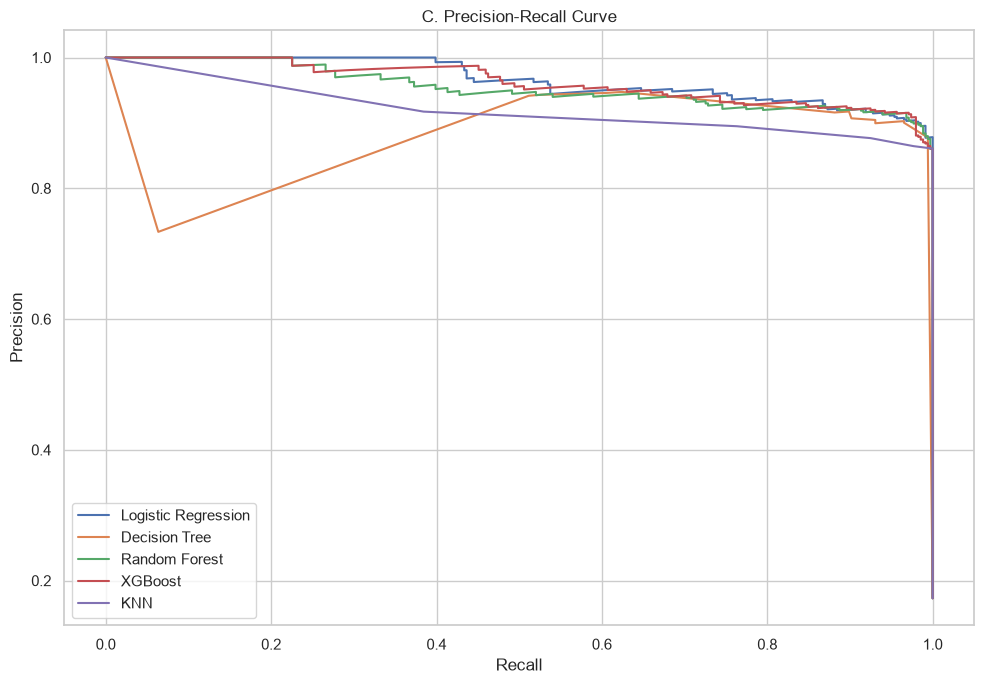

In [58]:
#Precision-Recall Curve

plt.figure(figsize=(10, 7))

for model_name, probabilities in models_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test_class,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=model_name
    )

plt.title("C. Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.tight_layout()
plt.show()

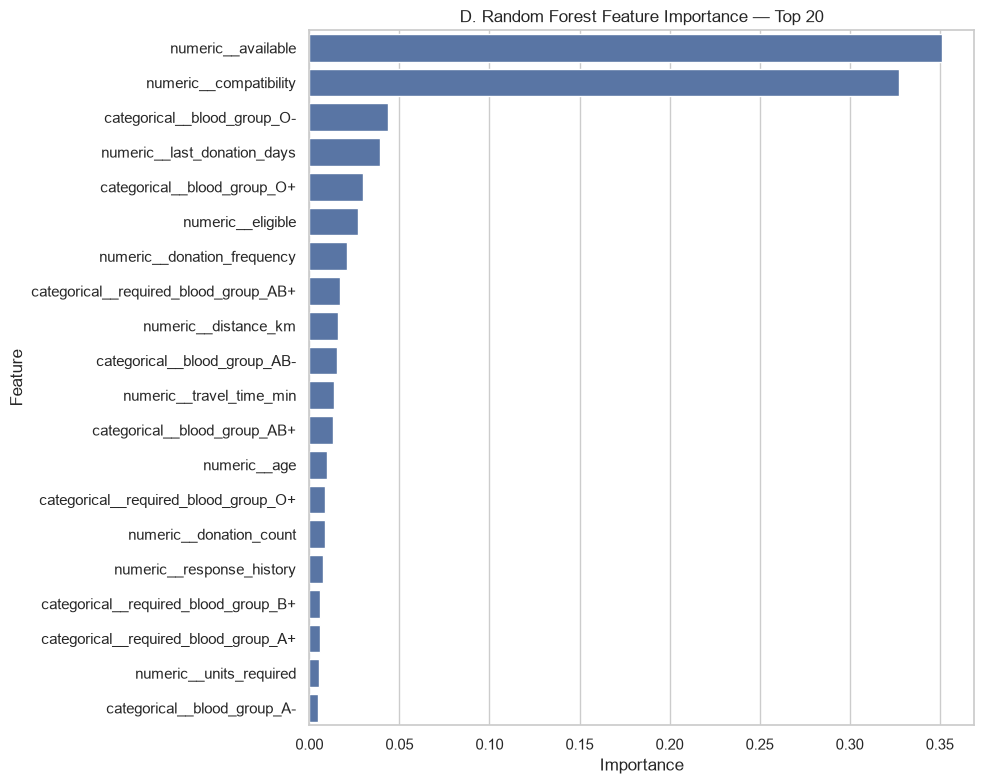

,Feature,Importance
0,numeric__available,0.351439
1,numeric__compatibility,0.327161
2,categorical__blood_group_O-,0.043636
3,numeric__last_donation_days,0.038986
4,categorical__blood_group_O+,0.029714
5,numeric__eligible,0.027134
6,numeric__donation_frequency,0.021035
7,categorical__required_blood_group_AB+,0.016902
8,numeric__distance_km,0.016125
9,categorical__blood_group_AB-,0.015488


In [59]:
# ============================================
# Cell 54 — Random Forest Feature Importance
# ============================================

# Get the trained Random Forest from the pipeline
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance DataFrame
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Sort by importance
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
top_rf_importance = rf_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_rf_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "D. Random Forest Feature Importance — Top 20"
)

plt.tight_layout()
plt.show()

display(top_rf_importance)

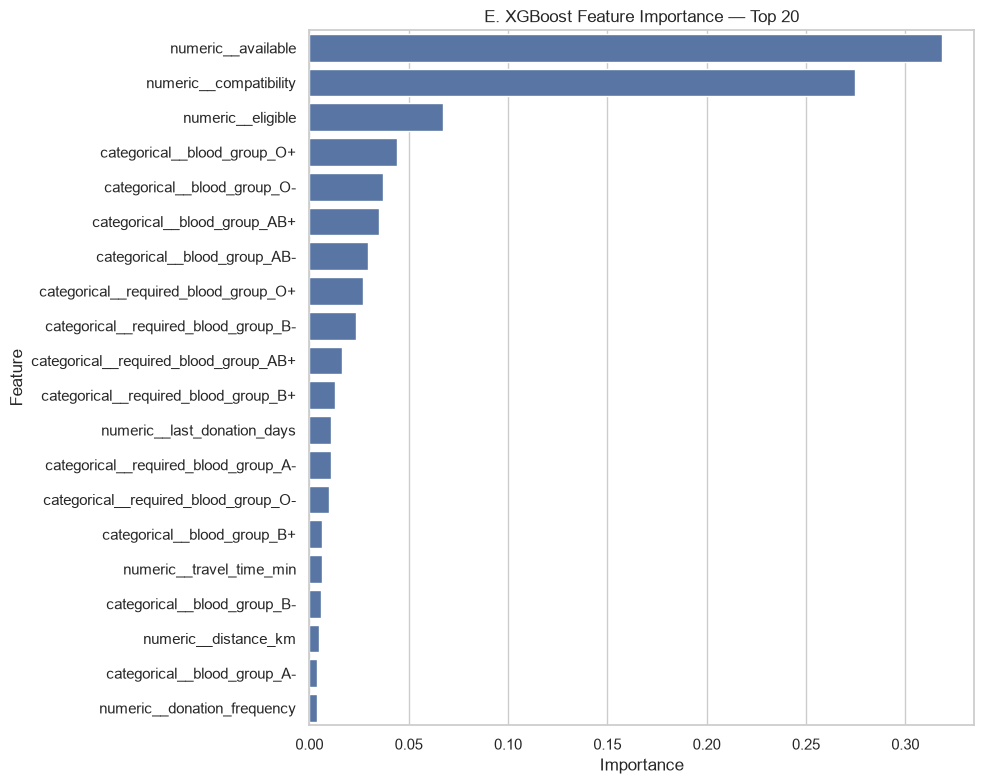

,Feature,Importance
0,numeric__available,0.318630
1,numeric__compatibility,0.274579
2,numeric__eligible,0.067250
3,categorical__blood_group_O+,0.043876
4,categorical__blood_group_O-,0.036955
5,categorical__blood_group_AB+,0.035214
6,categorical__blood_group_AB-,0.029692
7,categorical__required_blood_group_O+,0.026750
8,categorical__required_blood_group_B-,0.023495
9,categorical__required_blood_group_AB+,0.016598


In [60]:
# ============================================
# Cell 55 — XGBoost Feature Importance
# ============================================

# Get the trained XGBoost classifier from the pipeline
xgb_model = xgb_classifier.named_steps["classifier"]

# Get feature names after preprocessing
xgb_feature_names = (
    xgb_classifier
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance DataFrame
xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort by importance
xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
top_xgb_importance = xgb_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_xgb_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "E. XGBoost Feature Importance — Top 20"
)

plt.tight_layout()
plt.show()

display(top_xgb_importance)

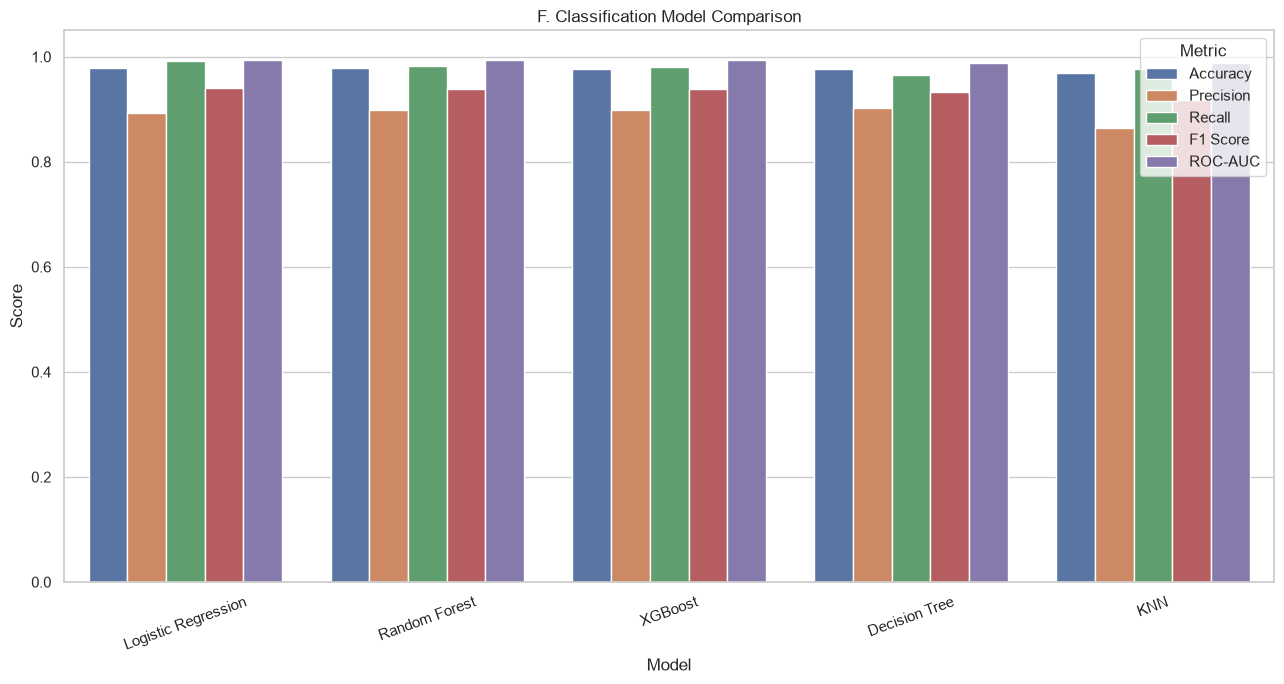

In [61]:
#Classification Model Comparison

comparison_melted = classification_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=comparison_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("F. Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")

plt.xticks(rotation=20)

plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

In [62]:
# ============================================
# Cell 57 — Prepare Regression Dataset
# ============================================

# --------------------------------------------
# Regression Target
# --------------------------------------------
# Target: travel_time_min
# We predict the estimated travel time in minutes.

y_reg = df["travel_time_min"].astype(float)

# --------------------------------------------
# Regression Features
# --------------------------------------------

regression_features = [
    "age",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "units_required",
    "response_history",
    "distance_km",
    "compatibility",
    "donation_frequency"
]

# Keep only features that exist in the dataset
available_regression_features = [
    col
    for col in regression_features
    if col in df.columns
]

# --------------------------------------------
# Create Regression Feature Dataset
# --------------------------------------------

X_reg = df[
    available_regression_features
].copy()

# --------------------------------------------
# Dataset Information
# --------------------------------------------

print("Regression Target:")
print("travel_time_min")

print("\nX Shape:", X_reg.shape)
print("y Shape:", y_reg.shape)

print("\nRegression Features:")
print(available_regression_features)

print("\nTarget Statistics:")
print(y_reg.describe())

print("\nMissing Values in X:")
print(X_reg.isnull().sum().sum())

print("\nFeature Preview:")
display(X_reg.head())

Regression Target:
travel_time_min

X Shape: (10000, 10)
y Shape: (10000,)

Regression Features:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'response_history', 'distance_km', 'compatibility', 'donation_frequency']

Target Statistics:
count    10000.000000
mean        34.227200
std         18.626118
min          5.000000
25%         20.000000
50%         32.000000
75%         46.000000
max        123.000000
Name: travel_time_min, dtype: float64

Missing Values in X:
0

Feature Preview:


,age,donation_count,last_donation_days,eligible,available,units_required,response_history,distance_km,compatibility,donation_frequency
0,18,35,179,1,0,1,0,12.59,1,5.83
1,27,31,24,0,0,1,7,10.97,0,37.20
2,45,8,295,1,1,1,9,27.42,0,0.81
3,54,6,294,1,1,1,9,13.75,0,0.61
4,27,20,43,0,0,1,9,12.24,0,13.64


In [63]:
# ============================================
# Cell 57 — Prepare Regression Dataset
# ============================================

# --------------------------------------------
# Regression Target
# --------------------------------------------
# Target: travel_time_min
# We predict travel time in minutes.

y_reg = df["travel_time_min"].astype(float)

# --------------------------------------------
# Regression Features
# --------------------------------------------

regression_features = [
    "age",
    "gender",
    "blood_group",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "units_required",
    "urgency",
    "distance_km",
    "response_history",
    "compatibility",
    "donation_frequency"
]

# Keep only columns that actually exist
available_regression_features = [
    col
    for col in regression_features
    if col in df.columns
]

# --------------------------------------------
# Create Regression Dataset
# --------------------------------------------

X_reg = df[
    available_regression_features
].copy()

# --------------------------------------------
# Dataset Information
# --------------------------------------------

print("Regression Target:")
print("travel_time_min")

print("\nRegression Features:")
print(available_regression_features)

print("\nX Shape:", X_reg.shape)
print("y Shape:", y_reg.shape)

print("\nTarget Statistics:")
print(y_reg.describe())

print("\nMissing Values in X:")
print(X_reg.isnull().sum().sum())

print("\nFeature Data Types:")
print(X_reg.dtypes)

print("\nFeature Preview:")
display(X_reg.head())

Regression Target:
travel_time_min

Regression Features:
['age', 'gender', 'blood_group', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'urgency', 'distance_km', 'response_history', 'compatibility', 'donation_frequency']

X Shape: (10000, 13)
y Shape: (10000,)

Target Statistics:
count    10000.000000
mean        34.227200
std         18.626118
min          5.000000
25%         20.000000
50%         32.000000
75%         46.000000
max        123.000000
Name: travel_time_min, dtype: float64

Missing Values in X:
0

Feature Data Types:
age                     int64
gender                    str
blood_group               str
donation_count          int64
last_donation_days      int64
eligible                int64
available               int64
units_required          int64
urgency                   str
distance_km           float64
response_history        int64
compatibility           int64
donation_frequency    float64
dtype: object

Feature Preview:


,age,gender,blood_group,donation_count,last_donation_days,eligible,available,units_required,urgency,distance_km,response_history,compatibility,donation_frequency
0,18,Female,O-,35,179,1,0,1,Medium,12.59,0,1,5.83
1,27,Male,A+,31,24,0,0,1,Medium,10.97,7,0,37.20
2,45,Male,AB-,8,295,1,1,1,Medium,27.42,9,0,0.81
3,54,Male,AB+,6,294,1,1,1,Medium,13.75,9,0,0.61
4,27,Female,A-,20,43,0,0,1,Medium,12.24,9,0,13.64


In [64]:
#train/test split regression

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training:", X_train_reg.shape)
print("Testing:", X_test_reg.shape)
print("X_train:", X_train_reg.shape)
print("X_test :", X_test_reg.shape)
print("y_train:", y_train_reg.shape)
print("y_test :", y_test_reg.shape)

Training: (8000, 13)
Testing: (2000, 13)
X_train: (8000, 13)
X_test : (2000, 13)
y_train: (8000,)
y_test : (2000,)


In [65]:
# ============================================
# Cell 59 — Regression Preprocessing Setup
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --------------------------------------------
# Identify Categorical Features
# --------------------------------------------

categorical_features_reg = [
    "gender",
    "blood_group",
    "urgency"
]

# Keep only existing columns
categorical_features_reg = [
    col
    for col in categorical_features_reg
    if col in X_train_reg.columns
]

# --------------------------------------------
# Identify Numerical Features
# --------------------------------------------

numerical_features_reg = [
    col
    for col in X_train_reg.columns
    if col not in categorical_features_reg
]

# --------------------------------------------
# Numerical Preprocessing
# --------------------------------------------

numeric_pipeline_reg = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# --------------------------------------------
# Categorical Preprocessing
# --------------------------------------------

categorical_pipeline_reg = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# --------------------------------------------
# Combined Regression Preprocessor
# --------------------------------------------

preprocessor_reg = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline_reg,
            numerical_features_reg
        ),
        (
            "categorical",
            categorical_pipeline_reg,
            categorical_features_reg
        )
    ]
)

print("Regression preprocessing pipeline created.")

print("\nNumerical features:")
print(numerical_features_reg)

print("\nCategorical features:")
print(categorical_features_reg)

Regression preprocessing pipeline created.

Numerical features:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'distance_km', 'response_history', 'compatibility', 'donation_frequency']

Categorical features:
['gender', 'blood_group', 'urgency']


In [66]:
# ============================================
# Cell 60 — Linear Regression
# ============================================

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# --------------------------------------------
# Create Linear Regression Pipeline
# --------------------------------------------

linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reg),
        ("regressor", LinearRegression())
    ]
)

# --------------------------------------------
# Train Model
# --------------------------------------------

linear_regression_model.fit(
    X_train_reg,
    y_train_reg
)

# --------------------------------------------
# Predictions
# --------------------------------------------

linear_predictions = linear_regression_model.predict(
    X_test_reg
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


In [67]:
# ============================================
# Cell 61 — Decision Tree Regressor
# ============================================

from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

# --------------------------------------------
# Create Decision Tree Regression Pipeline
# --------------------------------------------

decision_tree_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reg),
        (
            "regressor",
            DecisionTreeRegressor(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

# --------------------------------------------
# Train Model
# --------------------------------------------

decision_tree_regressor.fit(
    X_train_reg,
    y_train_reg
)

# --------------------------------------------
# Predictions
# --------------------------------------------

dt_reg_predictions = decision_tree_regressor.predict(
    X_test_reg
)

print("Decision Tree Regressor trained successfully.")

Decision Tree Regressor trained successfully.


In [68]:
# ============================================
# Cell 62 — Random Forest Regressor
# ============================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# --------------------------------------------
# Create Random Forest Regression Pipeline
# --------------------------------------------

random_forest_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reg),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=10,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# --------------------------------------------
# Train Model
# --------------------------------------------

random_forest_regressor.fit(
    X_train_reg,
    y_train_reg
)

# --------------------------------------------
# Predictions
# --------------------------------------------

rf_reg_predictions = random_forest_regressor.predict(
    X_test_reg
)

print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


In [69]:
# ============================================
# Cell 63 — XGBoost Regressor
# ============================================

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

# --------------------------------------------
# Create XGBoost Regression Pipeline
# --------------------------------------------

xgb_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reg),
        (
            "regressor",
            XGBRegressor(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42
            )
        )
    ]
)

# --------------------------------------------
# Train Model
# --------------------------------------------

xgb_regressor.fit(
    X_train_reg,
    y_train_reg
)

# --------------------------------------------
# Predictions
# --------------------------------------------

xgb_reg_predictions = xgb_regressor.predict(
    X_test_reg
)

print("XGBoost Regressor trained successfully.")

XGBoost Regressor trained successfully.


In [70]:
# ============================================
# Cell 64 — KNN Regressor
# ============================================

from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline

# --------------------------------------------
# Create KNN Regression Pipeline
# --------------------------------------------

knn_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reg),
        (
            "regressor",
            KNeighborsRegressor(
                n_neighbors=7
            )
        )
    ]
)

# --------------------------------------------
# Train Model
# --------------------------------------------

knn_regressor.fit(
    X_train_reg,
    y_train_reg
)

# --------------------------------------------
# Predictions
# --------------------------------------------

knn_reg_predictions = knn_regressor.predict(
    X_test_reg
)

print("KNN Regressor trained successfully.")

KNN Regressor trained successfully.


In [71]:
# regression evaluation function

def evaluate_regressor(
    model_name,
    y_true,
    predictions
):

    mae = mean_absolute_error(
        y_true,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            predictions
        )
    )

    r2 = r2_score(
        y_true,
        predictions
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [72]:
# regression model comparison

regression_results = []

regression_results.append(
    evaluate_regressor(
        "Linear Regression",
        y_test_reg,
        linear_predictions
    )
)

regression_results.append(
    evaluate_regressor(
        "Decision Tree",
        y_test_reg,
        dt_reg_predictions
    )
)

regression_results.append(
    evaluate_regressor(
        "Random Forest",
        y_test_reg,
        rf_reg_predictions
    )
)

regression_results.append(
    evaluate_regressor(
        "XGBoost",
        y_test_reg,
        xgb_reg_predictions
    )
)

regression_results.append(
    evaluate_regressor(
        "KNN",
        y_test_reg,
        knn_reg_predictions
    )
)

regression_results_df = pd.DataFrame(
    regression_results
)

regression_results_df = (
    regression_results_df
    .sort_values(
        by="RMSE",
        ascending=True
    )
    .reset_index(drop=True)
)

display(regression_results_df)

,Model,MAE,RMSE,R2
0,Random Forest,0.011120,0.104759,0.999968
1,Decision Tree,0.008221,0.106300,0.999967
2,Linear Regression,0.287103,0.420933,0.999476
3,XGBoost,0.317228,0.501046,0.999258
4,KNN,5.500286,6.939336,0.857673


In [73]:
# select best regressor

best_regressor_name = (
    regression_results_df
    .iloc[0]["Model"]
)

regression_prediction_dictionary = {
    "Linear Regression": linear_predictions,
    "Decision Tree": dt_reg_predictions,
    "Random Forest": rf_reg_predictions,
    "XGBoost": xgb_reg_predictions,
    "KNN": knn_reg_predictions
}

best_regression_predictions = (
    regression_prediction_dictionary[
        best_regressor_name
    ]
)

print(
    "Best Regression Model:",
    best_regressor_name
)

Best Regression Model: Random Forest


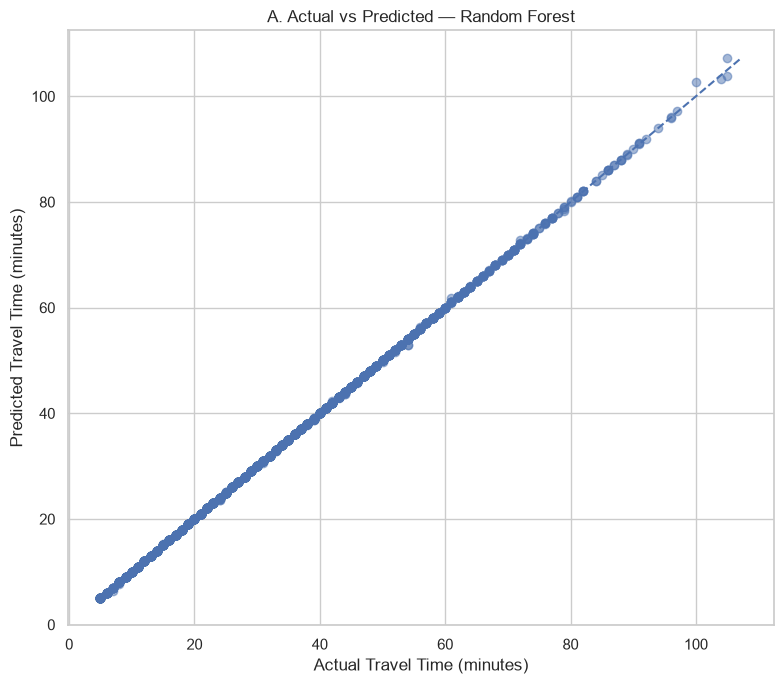

In [74]:
#Actual vs Predicted
plt.figure(figsize=(8, 7))

plt.scatter(
    y_test_reg,
    best_regression_predictions,
    alpha=0.5
)

min_value = min(
    y_test_reg.min(),
    best_regression_predictions.min()
)

max_value = max(
    y_test_reg.max(),
    best_regression_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(
    f"A. Actual vs Predicted — {best_regressor_name}"
)

plt.xlabel("Actual Travel Time (minutes)")
plt.ylabel("Predicted Travel Time (minutes)")

plt.tight_layout()
plt.show()

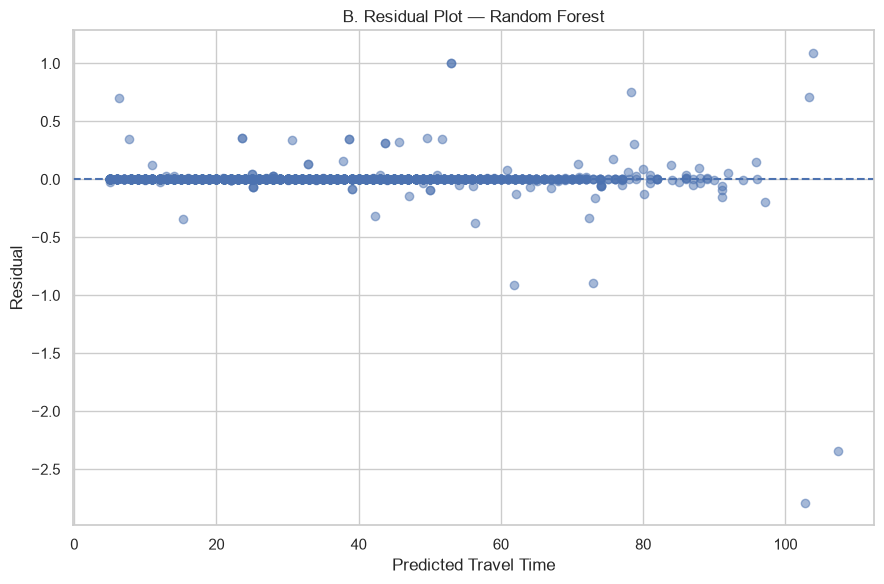

In [75]:
# residual plot
residuals = (
    y_test_reg.values
    -
    best_regression_predictions
)

plt.figure(figsize=(9, 6))

plt.scatter(
    best_regression_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    f"B. Residual Plot — {best_regressor_name}"
)

plt.xlabel("Predicted Travel Time")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

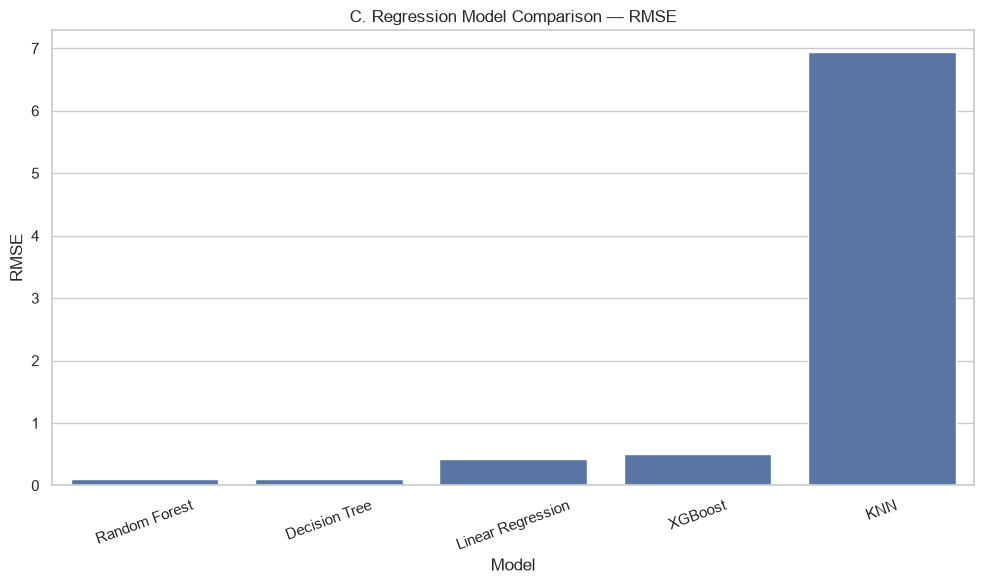

In [76]:
# regression model comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=regression_results_df,
    x="Model",
    y="RMSE"
)

plt.title("C. Regression Model Comparison — RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

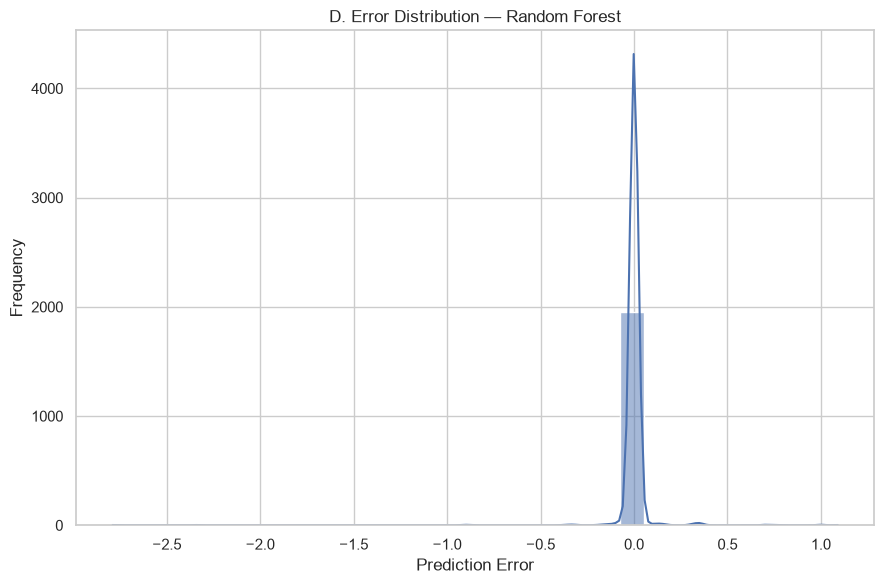

In [77]:
# Error distribution

plt.figure(figsize=(9, 6))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title(
    f"D. Error Distribution — {best_regressor_name}"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [78]:
# ============================================
# Cell 72 — Install PyTorch
# ============================================

%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [79]:
# ============================================
# Cell 73 — Check PyTorch Installation
# ============================================

%pip show torch

Name: torch
Version: 2.13.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND MIT
Location: C:\Users\amare\anaconda3\envs\tensorflow_env\Lib\site-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: torchvision, ultralytics, ultralytics-thop
Note: you may need to restart the kernel to use updated packages.


In [80]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.13.0+cpu
CUDA available: False


In [81]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\amare\anaconda3\envs\tensorflow_env\python.exe
3.12.13 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:26:47) [MSC v.1942 64 bit (AMD64)]


import sys
!{sys.executable} -m pip install torch torchvision torchaudio

# ADVANCED AI SETUP

In [82]:
# ADVANCED AI SETUP


# ============================================
# ADVANCED AI LAYER
# Transformer + GraphSAGE
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

PyTorch version: 2.13.0+cpu
Device: cpu


# FEATURES

In [83]:
# ============================================
# Cell 76 — HYBRID AI FEATURES
# ============================================

# Use the SAME target as conventional classifiers
# Conventional models predict "matched"

hybrid_features = [
    "age",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "units_required",
    "response_history",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "donation_frequency"
]

hybrid_features = [
    col for col in hybrid_features
    if col in df.columns
]

X_hybrid = df[hybrid_features].copy()

# SAME TARGET AS CONVENTIONAL MODELS
y_hybrid = df["matched"].astype(int).copy()

print("Hybrid Features:")
print(hybrid_features)

print("\nX shape:", X_hybrid.shape)
print("y shape:", y_hybrid.shape)

print("\nTarget distribution:")
print(y_hybrid.value_counts())

Hybrid Features:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'units_required', 'response_history', 'distance_km', 'travel_time_min', 'compatibility', 'donation_frequency']

X shape: (10000, 11)
y shape: (10000,)

Target distribution:
matched
0    8272
1    1728
Name: count, dtype: int64


# SCALING

In [84]:
# ============================================
# HYBRID AI — TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# --------------------------------------------
# 1. First split: 70% Training + 30% Temporary
# --------------------------------------------

X_hybrid_train, X_hybrid_temp, y_hybrid_train, y_hybrid_temp = train_test_split(
    X_hybrid,
    y_hybrid,
    test_size=0.30,
    random_state=42,
    stratify=y_hybrid
)

# --------------------------------------------
# 2. Second split: 15% Validation + 15% Test
# --------------------------------------------

X_hybrid_val, X_hybrid_test, y_hybrid_val, y_hybrid_test = train_test_split(
    X_hybrid_temp,
    y_hybrid_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_hybrid_temp
)

# --------------------------------------------
# 3. Feature Scaling
# --------------------------------------------

hybrid_scaler = StandardScaler()

# Fit scaler ONLY on training data
X_hybrid_train_scaled = hybrid_scaler.fit_transform(
    X_hybrid_train
).astype(np.float32)

# Apply same scaler to validation and test
X_hybrid_val_scaled = hybrid_scaler.transform(
    X_hybrid_val
).astype(np.float32)

X_hybrid_test_scaled = hybrid_scaler.transform(
    X_hybrid_test
).astype(np.float32)

# --------------------------------------------
# 4. Convert target arrays
# --------------------------------------------

y_hybrid_train = y_hybrid_train.values.astype(np.float32)
y_hybrid_val = y_hybrid_val.values.astype(np.float32)
y_hybrid_test = y_hybrid_test.values.astype(np.int32)

# --------------------------------------------
# 5. Verify split
# --------------------------------------------

print("============================================")
print("HYBRID AI DATA SPLIT")
print("============================================")

print("Training samples   :", X_hybrid_train_scaled.shape[0])
print("Validation samples :", X_hybrid_val_scaled.shape[0])
print("Testing samples    :", X_hybrid_test_scaled.shape[0])

print("\nTraining features  :", X_hybrid_train_scaled.shape[1])
print("Validation features:", X_hybrid_val_scaled.shape[1])
print("Testing features   :", X_hybrid_test_scaled.shape[1])

print("\nTraining target    :", y_hybrid_train.shape)
print("Validation target  :", y_hybrid_val.shape)
print("Testing target     :", y_hybrid_test.shape)

print("\nTarget distribution:")
print("Training  :", np.bincount(y_hybrid_train.astype(int)))
print("Validation:", np.bincount(y_hybrid_val.astype(int)))
print("Testing   :", np.bincount(y_hybrid_test.astype(int)))

print("\nHybrid train/validation/test split and scaling verified successfully.")

HYBRID AI DATA SPLIT
Training samples   : 7000
Validation samples : 1500
Testing samples    : 1500

Training features  : 11
Validation features: 11
Testing features   : 11

Training target    : (7000,)
Validation target  : (1500,)
Testing target     : (1500,)

Target distribution:
Training  : [5790 1210]
Validation: [1241  259]
Testing   : [1241  259]

Hybrid train/validation/test split and scaling verified successfully.


# Train/Test Split

In [85]:
# ============================================
# HYBRID AI — SHAPE VERIFICATION
# ============================================

print("Hybrid Training   :", X_hybrid_train_scaled.shape)
print("Hybrid Validation :", X_hybrid_val_scaled.shape)
print("Hybrid Testing    :", X_hybrid_test_scaled.shape)

print("\nTraining target   :", y_hybrid_train.shape)
print("Validation target :", y_hybrid_val.shape)
print("Testing target    :", y_hybrid_test.shape)

print("\nHybrid train/validation/test split and scaling verified successfully.")

Hybrid Training   : (7000, 11)
Hybrid Validation : (1500, 11)
Hybrid Testing    : (1500, 11)

Training target   : (7000,)
Validation target : (1500,)
Testing target    : (1500,)

Hybrid train/validation/test split and scaling verified successfully.


# Temporal Feature Sequence

In [86]:
# ============================================
# HYBRID AI — DONOR / REQUEST FEATURE INDICES
# ============================================

# Donor-related features
donor_features = [
    "age",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "response_history",
    "donation_frequency"
]

# Request / matching-related features
request_features = [
    "units_required",
    "distance_km",
    "travel_time_min",
    "compatibility"
]

# Get their positions in the hybrid feature vector
donor_indices = [
    hybrid_features.index(col)
    for col in donor_features
]

request_indices = [
    hybrid_features.index(col)
    for col in request_features
]

print("============================================")
print("DONOR / REQUEST FEATURE MAPPING")
print("============================================")

print("\nHybrid features:")
for i, feature in enumerate(hybrid_features):
    print(f"{i}: {feature}")

print("\nDonor features:")
print(donor_features)

print("Donor indices:")
print(donor_indices)

print("\nRequest features:")
print(request_features)

print("Request indices:")
print(request_indices)

print("\nFeature mapping verified successfully.")

DONOR / REQUEST FEATURE MAPPING

Hybrid features:
0: age
1: donation_count
2: last_donation_days
3: eligible
4: available
5: units_required
6: response_history
7: distance_km
8: travel_time_min
9: compatibility
10: donation_frequency

Donor features:
['age', 'donation_count', 'last_donation_days', 'eligible', 'available', 'response_history', 'donation_frequency']
Donor indices:
[0, 1, 2, 3, 4, 6, 10]

Request features:
['units_required', 'distance_km', 'travel_time_min', 'compatibility']
Request indices:
[5, 7, 8, 9]

Feature mapping verified successfully.


# Donor Dataset

In [87]:
# ============================================
# HYBRID AI — DATASETS & DATALOADERS
# ============================================

import torch
from torch.utils.data import TensorDataset, DataLoader

# --------------------------------------------
# 1. Convert features to PyTorch tensors
# --------------------------------------------

X_train_tensor = torch.tensor(
    X_hybrid_train_scaled,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_hybrid_val_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_hybrid_test_scaled,
    dtype=torch.float32
)

# --------------------------------------------
# 2. Convert targets to PyTorch tensors
# --------------------------------------------

y_train_tensor = torch.tensor(
    y_hybrid_train,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_hybrid_val,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_hybrid_test,
    dtype=torch.float32
)

# --------------------------------------------
# 3. Create TensorDatasets
# --------------------------------------------

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# --------------------------------------------
# 4. Create DataLoaders
# --------------------------------------------

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# --------------------------------------------
# 5. Verify datasets and dataloaders
# --------------------------------------------

print("============================================")
print("HYBRID AI DATASETS & DATALOADERS")
print("============================================")

print("\nTrain dataset      :", len(train_dataset))
print("Validation dataset :", len(val_dataset))
print("Test dataset       :", len(test_dataset))

print("\nTrain batches      :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

print("\nBatch size         :", BATCH_SIZE)

print("\nInput batch shape  :",
      next(iter(train_loader))[0].shape)

print("Target batch shape:",
      next(iter(train_loader))[1].shape)

print("\nDatasets and DataLoaders created successfully.")

HYBRID AI DATASETS & DATALOADERS

Train dataset      : 7000
Validation dataset : 1500
Test dataset       : 1500

Train batches      : 110
Validation batches : 24
Test batches       : 24

Batch size         : 64

Input batch shape  : torch.Size([64, 11])
Target batch shape: torch.Size([64])

Datasets and DataLoaders created successfully.


# Temporal Transformer

In [88]:
# ============================================
# Cell 81 — IMPROVED FEATURE TRANSFORMER
# ============================================

class DonorTemporalTransformer(nn.Module):

    def __init__(
        self,
        n_features,
        hidden_dim=64,
        n_heads=4,
        n_layers=3,
        dropout=0.10
    ):

        super().__init__()

        # --------------------------------------------
        # Project each individual feature into embedding
        # --------------------------------------------
        self.value_projection = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )

        # --------------------------------------------
        # Learnable embedding for every feature
        # --------------------------------------------
        self.feature_embedding = nn.Parameter(
            torch.randn(
                1,
                n_features,
                hidden_dim
            ) * 0.02
        )

        # --------------------------------------------
        # Transformer Encoder
        # --------------------------------------------
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=n_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # --------------------------------------------
        # Final normalization
        # --------------------------------------------
        self.output_norm = nn.LayerNorm(hidden_dim)

        self.output_dim = hidden_dim

    def forward(self, x):

        # Input:
        # [batch_size, n_features]

        # Convert each feature into a token
        # [batch_size, n_features]
        # →
        # [batch_size, n_features, 1]

        x = x.unsqueeze(-1)

        # Feature-value projection
        x = self.value_projection(x)

        # Add feature identity embeddings
        x = x + self.feature_embedding

        # Transformer learns relationships
        # between donor/request features
        x = self.encoder(x)

        # Global feature representation
        x = x.mean(dim=1)

        # Normalize final representation
        x = self.output_norm(x)

        return x


print("Improved Feature Transformer class created successfully.")

Improved Feature Transformer class created successfully.


# GraphSAGE

In [89]:
# ============================================
# Cell 82 — IMPROVED GRAPH SAGE STYLE MATCHING
# ============================================

class MatchingGraphSAGE(nn.Module):

    def __init__(
        self,
        donor_dim,
        request_dim,
        hidden_dim=64
    ):

        super().__init__()

        # --------------------------------------------
        # Donor feature projection
        # --------------------------------------------

        self.donor_projection = nn.Sequential(
            nn.Linear(donor_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.10)
        )

        # --------------------------------------------
        # Request feature projection
        # --------------------------------------------

        self.request_projection = nn.Sequential(
            nn.Linear(request_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.10)
        )

        # --------------------------------------------
        # Donor + Request aggregation
        # --------------------------------------------

        self.aggregate = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.10)
        )

        # --------------------------------------------
        # Relationship refinement
        # --------------------------------------------

        self.refinement = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )

        self.output_dim = hidden_dim

    def forward(
        self,
        donor_features,
        request_features
    ):

        # Donor representation
        donor_embedding = self.donor_projection(
            donor_features
        )

        # Request representation
        request_embedding = self.request_projection(
            request_features
        )

        # Combine donor + request
        combined = torch.cat(
            [
                donor_embedding,
                request_embedding
            ],
            dim=1
        )

        # GraphSAGE-style aggregation
        output = self.aggregate(
            combined
        )

        # Learn higher-level relationship
        output = self.refinement(
            output
        )

        return output


print("Improved GraphSAGE-style matching branch created successfully.")

Improved GraphSAGE-style matching branch created successfully.


# Hybrid Model

In [90]:
# ============================================
# Cell 83 — IMPROVED HYBRID TRANSFORMER + GRAPHSAGE
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class ImprovedHybridAI(nn.Module):

    def __init__(
        self,
        n_features,
        donor_indices,
        request_indices,
        hidden_dim=64,
        num_heads=4,
        num_layers=2,
        dropout=0.15
    ):

        super().__init__()

        self.donor_indices = donor_indices
        self.request_indices = request_indices

        # ========================================
        # 1. FEATURE-LEVEL TRANSFORMER
        # ========================================

        self.feature_projection = nn.Linear(
            1,
            hidden_dim
        )

        self.feature_embedding = nn.Parameter(
            torch.randn(
                1,
                n_features,
                hidden_dim
            ) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.transformer_norm = nn.LayerNorm(
            hidden_dim
        )

        # ========================================
        # 2. DONOR REPRESENTATION
        # ========================================

        self.donor_projection = nn.Sequential(

            nn.Linear(
                len(donor_indices),
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ========================================
        # 3. REQUEST REPRESENTATION
        # ========================================

        self.request_projection = nn.Sequential(

            nn.Linear(
                len(request_indices),
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ========================================
        # 4. GRAPHSAGE-STYLE AGGREGATION
        # ========================================

        self.graphsage = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU()
        )

        # ========================================
        # 5. DONOR-REQUEST INTERACTION
        # ========================================

        self.interaction = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.GELU()
        )

        # ========================================
        # 6. MULTI-BRANCH FUSION
        # ========================================

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim * 3,
                hidden_dim * 2
            ),

            nn.LayerNorm(
                hidden_dim * 2
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ========================================
        # 7. FINAL CLASSIFIER
        # ========================================

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.LayerNorm(32),

            nn.GELU(),

            nn.Dropout(0.10),

            nn.Linear(
                32,
                1
            )
        )


    def forward(self, x):

        # ========================================
        # Transformer branch
        # ========================================

        # [batch, features]
        # → [batch, features, 1]

        transformer_input = x.unsqueeze(-1)

        # Project every feature
        transformer_input = self.feature_projection(
            transformer_input
        )

        # Add feature-specific embeddings

        transformer_input = (
            transformer_input
            + self.feature_embedding
        )

        # Transformer

        transformer_output = self.transformer(
            transformer_input
        )

        # Global feature representation

        transformer_output = transformer_output.mean(
            dim=1
        )

        transformer_output = self.transformer_norm(
            transformer_output
        )

        # ========================================
        # Donor branch
        # ========================================

        donor_x = x[:, self.donor_indices]

        donor_embedding = self.donor_projection(
            donor_x
        )

        # ========================================
        # Request branch
        # ========================================

        request_x = x[:, self.request_indices]

        request_embedding = self.request_projection(
            request_x
        )

        # ========================================
        # GraphSAGE-style aggregation
        # ========================================

        graph_input = torch.cat(
            [
                donor_embedding,
                request_embedding
            ],
            dim=1
        )

        graph_embedding = self.graphsage(
            graph_input
        )

        # ========================================
        # Direct donor-request interaction
        # ========================================

        interaction_embedding = self.interaction(
            graph_input
        )

        # ========================================
        # Multi-branch fusion
        # ========================================

        fused = torch.cat(
            [
                transformer_output,
                graph_embedding,
                interaction_embedding
            ],
            dim=1
        )

        fused = self.fusion(
            fused
        )

        # ========================================
        # Final prediction
        # ========================================

        output = self.classifier(
            fused
        )

        return output.squeeze(1)


print(
    "Improved Hybrid Transformer + GraphSAGE model created."
)

Improved Hybrid Transformer + GraphSAGE model created.


# Model Create

In [91]:
# ============================================
# Cell 84 — CREATE IMPROVED HYBRID MODEL
# ============================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Number of Hybrid input features
n_features = X_hybrid_train_scaled.shape[1]

# Create Hybrid Transformer + GraphSAGE model
hybrid_model = ImprovedHybridAI(
    n_features=n_features,
    donor_indices=donor_indices,
    request_indices=request_indices,
    hidden_dim=64,
    num_heads=4,
    num_layers=2,
    dropout=0.15
).to(device)

print("Device:", device)
print("Input features:", n_features)

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in hybrid_model.parameters()
    )
)

print("\nHybrid model created successfully.")

Device: cpu
Input features: 11
Total parameters: 162753

Hybrid model created successfully.


In [92]:
# ============================================
# NEW CELL — HYBRID DATA LOADERS
# ============================================

from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_hybrid_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_hybrid_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_hybrid_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_hybrid_test,
    dtype=torch.float32
)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

Train batches: 55
Test batches : 6


# Training

In [93]:
# ============================================
# Cell 85 — HYBRID AI TRAINING
# ============================================

import copy
import torch
import numpy as np

# --------------------------------------------
# 1. Device
# --------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

hybrid_model = hybrid_model.to(device)

# --------------------------------------------
# 2. Class weighting
# --------------------------------------------

num_negative = (y_hybrid_train == 0).sum()
num_positive = (y_hybrid_train == 1).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# --------------------------------------------
# 3. Optimizer
# --------------------------------------------

optimizer = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# --------------------------------------------
# 4. Learning-rate scheduler
# --------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

# --------------------------------------------
# 5. Training settings
# --------------------------------------------

EPOCHS = 100
PATIENCE = 12

training_losses = []
validation_losses = []

best_val_loss = float("inf")
best_state = None
patience_counter = 0

# --------------------------------------------
# 6. Training loop
# --------------------------------------------

for epoch in range(EPOCHS):

    # ============================
    # Training
    # ============================

    hybrid_model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        # Current model already returns [batch]
        logits = hybrid_model(X_batch)

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            hybrid_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += (
            loss.item() * X_batch.size(0)
        )

    train_loss /= len(train_loader.dataset)

    # ============================
    # Validation
    # ============================

    hybrid_model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = hybrid_model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            val_loss += (
                loss.item() * X_batch.size(0)
            )

    val_loss /= len(val_loader.dataset)

    # --------------------------------
    # Store losses
    # --------------------------------

    training_losses.append(train_loss)
    validation_losses.append(val_loss)

    # --------------------------------
    # Update learning rate
    # --------------------------------

    scheduler.step(val_loss)

    # --------------------------------
    # Save best model
    # --------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            hybrid_model.state_dict()
        )

        patience_counter = 0

    else:

        patience_counter += 1

    # --------------------------------
    # Print progress
    # --------------------------------

    if (epoch + 1) % 5 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1:03d}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    # --------------------------------
    # Early stopping
    # --------------------------------

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break

# --------------------------------------------
# 7. Restore best validation model
# --------------------------------------------

hybrid_model.load_state_dict(best_state)

print("\n============================================")
print("HYBRID AI TRAINING COMPLETED")
print("============================================")

print(
    "Best validation loss:",
    round(best_val_loss, 6)
)

print(
    "Best model restored successfully."
)

Epoch [001/100] Train Loss: 0.3968 | Val Loss: 0.2004 | LR: 0.001000
Epoch [005/100] Train Loss: 0.1418 | Val Loss: 0.1502 | LR: 0.001000
Epoch [010/100] Train Loss: 0.1226 | Val Loss: 0.1434 | LR: 0.001000
Epoch [015/100] Train Loss: 0.1231 | Val Loss: 0.1393 | LR: 0.001000
Epoch [020/100] Train Loss: 0.1190 | Val Loss: 0.1384 | LR: 0.001000
Epoch [025/100] Train Loss: 0.1189 | Val Loss: 0.1475 | LR: 0.001000
Epoch [030/100] Train Loss: 0.1184 | Val Loss: 0.1383 | LR: 0.000500
Epoch [035/100] Train Loss: 0.1180 | Val Loss: 0.1393 | LR: 0.000500
Epoch [040/100] Train Loss: 0.1192 | Val Loss: 0.1412 | LR: 0.000250

Early stopping at epoch 42

HYBRID AI TRAINING COMPLETED
Best validation loss: 0.13827
Best model restored successfully.


In [94]:
# ============================================
# TARGET RELATIONSHIP / LEAKAGE DIAGNOSTIC
# ============================================

print("TARGET: matched")
print("=" * 50)

print("\nMatched distribution:")
print(df["matched"].value_counts())

print("\nMatched percentage:")
print(df["matched"].value_counts(normalize=True) * 100)


# --------------------------------------------
# Compare numerical features by target
# --------------------------------------------

numeric_check = [
    "eligible",
    "available",
    "units_required",
    "response_history",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "donation_frequency",
    "distance_score",
    "eta_score",
    "match_score",
    "donor_rank"
]

numeric_check = [
    col for col in numeric_check
    if col in df.columns
]

print("\nMean feature values by matched:")
print(
    df.groupby("matched")[numeric_check]
      .mean()
      .round(4)
      .T
)


# --------------------------------------------
# Correlation with target
# --------------------------------------------

print("\nCorrelation with matched:")
correlation = (
    df[numeric_check + ["matched"]]
    .corr(numeric_only=True)["matched"]
    .sort_values(ascending=False)
)

print(correlation)

TARGET: matched

Matched distribution:
matched
0    8272
1    1728
Name: count, dtype: int64

Matched percentage:
matched
0    82.72
1    17.28
Name: proportion, dtype: float64

Mean feature values by matched:
matched                   0        1
eligible             0.8906   1.0000
available            0.4058   1.0000
units_required       5.5312   5.4259
response_history    10.1084  10.1458
distance_km         17.2569  16.3526
travel_time_min     34.5376  32.7413
compatibility        0.3230   1.0000
donation_frequency  16.5340   5.2612
distance_score       0.7186   0.7333
eta_score            0.7192   0.7338
match_score          0.1637   0.8318
donor_rank           6.2935   1.7014

Correlation with matched:
matched               1.000000
match_score           0.711643
compatibility         0.515625
available             0.449348
eligible              0.144175
distance_score        0.036595
eta_score             0.036464
response_history      0.002342
units_required       -0.013673
tra

In [95]:
# ============================================
# MATCHED vs MATCHING CONDITIONS
# ============================================

print("Matched = 1 conditions")
print("=" * 50)

for col in [
    "eligible",
    "available",
    "compatibility"
]:
    print(f"\n{col}:")
    print(
        pd.crosstab(
            df[col],
            df["matched"],
            normalize="index"
        ).round(4)
    )


print("\nMatch status vs matched:")
print(
    pd.crosstab(
        df["match_status"],
        df["matched"]
    )
)


print("\nMatch score statistics by matched:")
print(
    df.groupby("matched")["match_score"]
      .describe()
      .round(4)
)


print("\nDonor rank statistics by matched:")
print(
    df.groupby("matched")["donor_rank"]
      .describe()
      .round(4)
)

Matched = 1 conditions

eligible:
matched      0     1
eligible            
0         1.00  0.00
1         0.81  0.19

available:
matched         0       1
available                
0          1.0000  0.0000
1          0.6602  0.3398

compatibility:
matched             0       1
compatibility                
0              1.0000  0.0000
1              0.6073  0.3927

Match status vs matched:
matched                      0     1
match_status                        
Blood Group Incompatible  5600     0
Low Match Score            295     0
Matched                      0  1728
Not Available             1951     0
Not Eligible               426     0

Match score statistics by matched:
          count    mean     std   min    25%     50%    75%    max
matched                                                           
0        8272.0  0.1637  0.2725  0.00  0.000  0.0000  0.481  0.888
1        1728.0  0.8318  0.0671  0.65  0.787  0.8345  0.880  0.996

Donor rank statistics by matched:
      

# Training Loss Graph

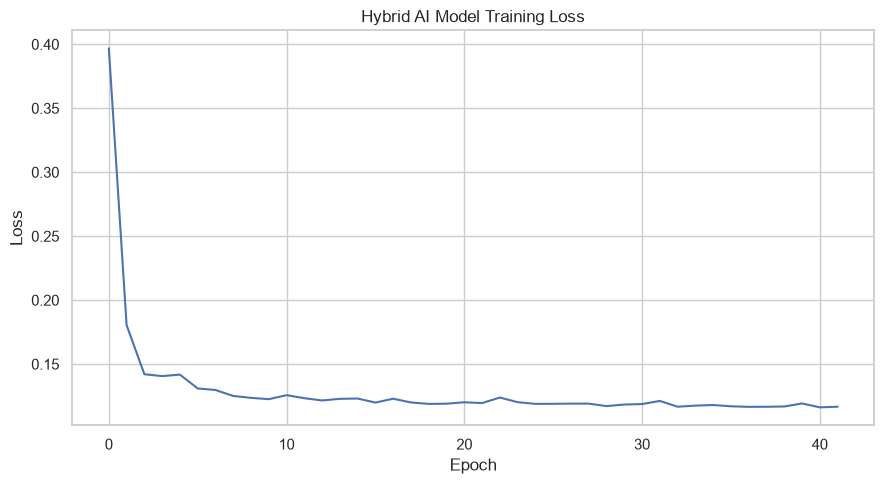

In [96]:
# ============================================
# TRAINING LOSS
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(
    training_losses
)

plt.title(
    "Hybrid AI Model Training Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.tight_layout()

plt.show()

# Hybrid Model Evaluation

In [97]:
# ============================================
# HYBRID AI — TEST SET EVALUATION
# ============================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

hybrid_model.eval()

all_probs = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        logits = hybrid_model(X_batch)
        probs = torch.sigmoid(logits)

        all_probs.extend(probs.cpu().numpy())
        all_true.extend(y_batch.numpy())

all_probs = np.array(all_probs)
all_true = np.array(all_true).astype(int)

# Default threshold
threshold = 0.50

all_pred = (all_probs >= threshold).astype(int)

accuracy = accuracy_score(all_true, all_pred)
precision = precision_score(all_true, all_pred, zero_division=0)
recall = recall_score(all_true, all_pred, zero_division=0)
f1 = f1_score(all_true, all_pred, zero_division=0)
roc_auc = roc_auc_score(all_true, all_probs)

print("============================================")
print("HYBRID AI TEST SET RESULTS")
print("============================================")

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(all_true, all_pred))

print("\nClassification Report:")
print(classification_report(
    all_true,
    all_pred,
    digits=4,
    zero_division=0
))

HYBRID AI TEST SET RESULTS
Accuracy  : 0.9693 (96.93%)
Precision : 0.8492
Recall    : 1.0000
F1-Score  : 0.9184
ROC-AUC   : 0.9896

Confusion Matrix:
[[1195   46]
 [   0  259]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9629    0.9811      1241
           1     0.8492    1.0000    0.9184       259

    accuracy                         0.9693      1500
   macro avg     0.9246    0.9815    0.9498      1500
weighted avg     0.9740    0.9693    0.9703      1500



In [102]:
# ==========================================
# CLASSIFICATION MODEL COMPARISON
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd


def get_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


results = []


# Logistic Regression
m = get_metrics(
    y_test_class,
    logistic_predictions,
    logistic_probabilities
)
m["Model"] = "Logistic Regression"
results.append(m)


# Decision Tree
m = get_metrics(
    y_test_class,
    dt_predictions,
    dt_probabilities
)
m["Model"] = "Decision Tree"
results.append(m)


# Random Forest
m = get_metrics(
    y_test_class,
    rf_predictions,
    rf_probabilities
)
m["Model"] = "Random Forest"
results.append(m)


# XGBoost
m = get_metrics(
    y_test_class,
    xgb_predictions,
    xgb_probabilities
)
m["Model"] = "XGBoost"
results.append(m)


# KNN
m = get_metrics(
    y_test_class,
    knn_predictions,
    knn_probabilities
)
m["Model"] = "KNN"
results.append(m)


# Hybrid AI
m = get_metrics(
    all_true,
    all_pred,
    all_probs
)
m["Model"] = "Hybrid AI"
results.append(m)


# Comparison table
model_results = pd.DataFrame(results)

model_results = model_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

model_results = model_results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

model_results[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
] = model_results[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
].round(4)

display(model_results)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9780,0.8932,0.9913,0.9397,0.9942
1,Random Forest,0.9780,0.8995,0.9827,0.9392,0.9928
2,XGBoost,0.9775,0.8992,0.9798,0.9378,0.9937
3,Decision Tree,0.9760,0.9027,0.9653,0.9330,0.9880
4,Hybrid AI,0.9693,0.8492,1.0000,0.9184,0.9896
5,KNN,0.9695,0.8645,0.9769,0.9172,0.9877


# Confusion Matrix

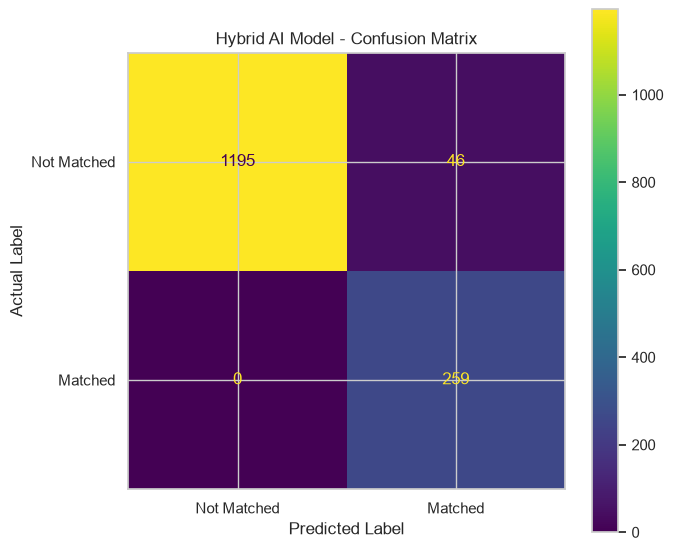

In [103]:
# ============================================
# HYBRID MODEL CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_hybrid = confusion_matrix(
    all_true,
    all_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hybrid,
    display_labels=[
        "Not Matched",
        "Matched"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title("Hybrid AI Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# ROC Curve

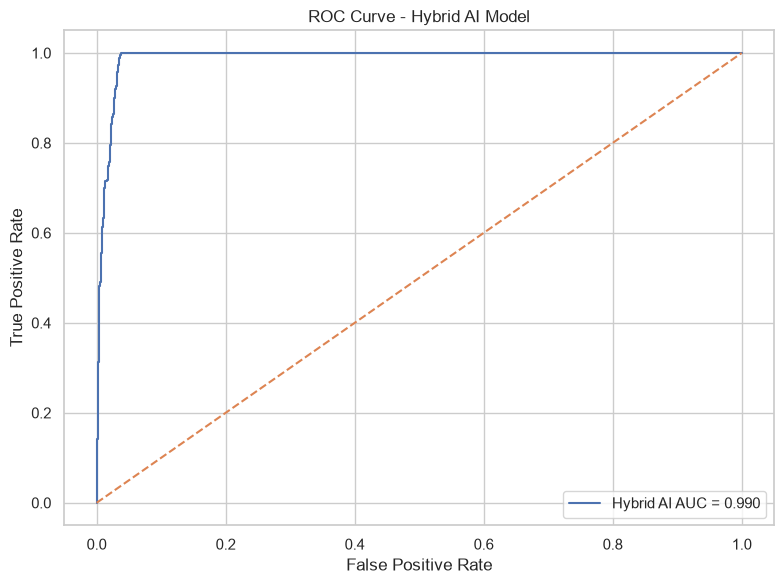

In [104]:
# ============================================
# HYBRID MODEL ROC CURVE
# ============================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(
    all_true,
    all_probs
)

hybrid_auc = roc_auc_score(
    all_true,
    all_probs
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Hybrid AI AUC = {hybrid_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Hybrid AI Model")

plt.legend()
plt.tight_layout()
plt.show()

# AI Match Score

In [105]:
# ============================================
# Cell 90 — AI-ENHANCED MATCH SCORE
# ============================================

import numpy as np
import torch

# --------------------------------------------
# Prepare all data using the SAME
# Hybrid features used during training
# --------------------------------------------

X_all_hybrid = df[hybrid_features].copy()

X_all_hybrid_scaled = hybrid_scaler.transform(
    X_all_hybrid
).astype(np.float32)

all_tensor = torch.tensor(
    X_all_hybrid_scaled,
    dtype=torch.float32
).to(device)


# --------------------------------------------
# Generate Hybrid AI probabilities
# --------------------------------------------

hybrid_model.eval()

with torch.no_grad():

    all_logits = hybrid_model(
        all_tensor
    )

    ai_match_probability = (
        torch.sigmoid(all_logits)
        .cpu()
        .numpy()
    )


# --------------------------------------------
# Store AI matching probability
# --------------------------------------------

df["ai_match_probability"] = (
    ai_match_probability
)


# ============================================
# RESPONSE SCORE
# ============================================

max_response = df["response_history"].max()

if max_response > 0:

    df["response_score"] = (
        df["response_history"]
        / max_response
    ).clip(0, 1)

else:

    df["response_score"] = 0.0


# ============================================
# AI-ENHANCED MATCH SCORE
# ============================================

df["ai_match_score"] = (

    0.30 * df["compatibility"]

    +

    0.15 * df["available"]

    +

    0.15 * df["distance_score"]

    +

    0.15 * df["eta_score"]

    +

    0.10 * df["response_score"]

    +

    0.15 * df["ai_match_probability"]

)


# --------------------------------------------
# Keep score between 0 and 1
# --------------------------------------------

df["ai_match_score"] = (
    df["ai_match_score"]
    .clip(0, 1)
    .round(4)
)


# ============================================
# VERIFY CREATED COLUMNS
# ============================================

print("AI-enhanced matching score calculated successfully.")

print(
    "\nAI Match Probability range:",
    round(df["ai_match_probability"].min(), 4),
    "to",
    round(df["ai_match_probability"].max(), 4)
)

print(
    "AI Match Score range:",
    round(df["ai_match_score"].min(), 4),
    "to",
    round(df["ai_match_score"].max(), 4)
)


# ============================================
# DISPLAY RESULTS
# ============================================

display(
    df[
        [
            "donor_id",
            "request_id",
            "compatibility",
            "available",
            "distance_score",
            "eta_score",
            "ai_match_probability",
            "ai_match_score"
        ]
    ].head(10)
)

AI-enhanced matching score calculated successfully.

AI Match Probability range: 1e-04 to 0.9892
AI Match Score range: 0.035 to 0.9886


,donor_id,request_id,compatibility,available,distance_score,eta_score,ai_match_probability,ai_match_score
0,93246afe6c,1001,1,0,0.795,0.797,0.000147,0.5388
1,1b8b4c828a,1001,0,0,0.821,0.821,0.000147,0.2813
2,a6a3f7fe55,1001,0,1,0.553,0.553,0.000146,0.3609
3,cee6478144,1001,0,1,0.776,0.772,0.000146,0.4272
4,5986bc55f9,1001,0,0,0.800,0.805,0.000147,0.2858
5,486ffe4e4a,1001,0,0,0.733,0.732,0.000147,0.2298
6,32e4e74c30,1001,0,1,0.837,0.837,0.000146,0.4861
7,62927f7975,1001,0,0,0.834,0.837,0.000147,0.3257
8,17a47b3f43,1001,0,0,0.894,0.894,0.000147,0.3332
9,c6f6371120,1001,0,1,0.994,0.959,0.000146,0.5430


# AI Donor Ranking

In [106]:
# ============================================
# AI-BASED DONOR RANKING
# ============================================

df["ai_donor_rank"] = (
    df.groupby("request_id")["ai_match_score"]
      .rank(
          method="first",
          ascending=False
      )
      .astype(int)
)

print("AI donor ranking completed.")

display(
    df[
        [
            "request_id",
            "donor_id",
            "blood_group",
            "required_blood_group",
            "ai_match_probability",
            "ai_match_score",
            "ai_donor_rank"
        ]
    ]
    .sort_values(
        [
            "request_id",
            "ai_donor_rank"
        ]
    )
    .head(20)
)

AI donor ranking completed.


,request_id,donor_id,blood_group,required_blood_group,ai_match_probability,ai_match_score,ai_donor_rank
9,1001,c6f6371120,AB+,O+,0.000146,0.5430,1
0,1001,93246afe6c,O-,O+,0.000147,0.5388,2
6,1001,32e4e74c30,B-,O+,0.000146,0.4861,3
3,1001,cee6478144,AB+,O+,0.000146,0.4272,4
2,1001,a6a3f7fe55,AB-,O+,0.000146,0.3609,5
8,1001,17a47b3f43,B-,O+,0.000147,0.3332,6
7,1001,62927f7975,AB-,O+,0.000147,0.3257,7
4,1001,5986bc55f9,A-,O+,0.000147,0.2858,8
1,1001,1b8b4c828a,A+,O+,0.000147,0.2813,9
5,1001,486ffe4e4a,A+,O+,0.000147,0.2298,10


# Final Top 3 Donors

In [107]:
# ============================================
# FINAL AI TOP-3 DONOR RECOMMENDATION
# ============================================

final_ai_recommendations = (

    df[
        (df["eligible"] == 1)
        &
        (df["available"] == 1)
        &
        (df["compatibility"] == 1)
    ]

    .sort_values(
        [
            "request_id",
            "ai_match_score"
        ],
        ascending=[
            True,
            False
        ]
    )

    .groupby(
        "request_id"
    )

    .head(3)

    .copy()
)

# Add recommendation label
final_ai_recommendations[
    "recommendation"
] = "AI Recommended"

# ============================================
# FINAL OUTPUT COLUMNS
# ============================================

final_columns = [
    "request_id",
    "donor_id",
    "blood_group",
    "required_blood_group",
    "age",
    "available",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "ai_match_probability",
    "ai_match_score",
    "ai_donor_rank",
    "recommendation"
]

display(
    final_ai_recommendations[
        final_columns
    ].head(30)
)

,request_id,donor_id,blood_group,required_blood_group,age,available,distance_km,travel_time_min,compatibility,ai_match_probability,ai_match_score,ai_donor_rank,recommendation
10,1002,d3cf2f45e3,B-,B+,62,1,11.51,23,1,0.977702,0.9104,1,AI Recommended
12,1002,f156dbaba5,B-,B+,27,1,14.25,28,1,0.981775,0.8983,2,AI Recommended
11,1002,f89330b850,O-,B+,49,1,8.84,18,1,0.980878,0.8586,3,AI Recommended
30,1004,cd9e28dfdd,O+,O+,33,1,9.01,18,1,0.982903,0.9085,1,AI Recommended
31,1004,e61bb198e6,O-,O+,41,1,24.15,48,1,0.932701,0.7773,2,AI Recommended
40,1005,45494a599c,B+,B+,41,1,8.68,17,1,0.984658,0.8757,1,AI Recommended
51,1006,1ab37e044c,O+,A+,59,1,18.74,37,1,0.958697,0.8678,1,AI Recommended
50,1006,28275acb69,O+,A+,46,1,18.39,37,1,0.972622,0.8557,2,AI Recommended
61,1007,30794b3812,A+,AB+,60,1,2.07,5,1,0.987757,0.9669,1,AI Recommended
63,1007,57cb8819a9,A-,AB+,42,1,11.41,23,1,0.982513,0.9414,2,AI Recommended


# Final System Summary

In [108]:
# ============================================
# FINAL AI SYSTEM SUMMARY
# ============================================

print("=" * 70)
print(" BLOOD EMERGENCY & DONOR MATCHING")
print(" HYBRID AI SYSTEM")
print("=" * 70)

print(
    f"\nTotal Records        : {len(df):,}"
)

print(
    f"Unique Donors        : {df['donor_id'].nunique():,}"
)

print(
    f"Blood Requests       : {df['request_id'].nunique():,}"
)

print(
    f"Eligible Donors      : {df['eligible'].sum():,}"
)

print(
    f"Available Donors     : {df['available'].sum():,}"
)

print(
    f"Compatible Pairs     : {df['compatibility'].sum():,}"
)

print("\nAI Architecture:")
print("1. Temporal Transformer")
print("2. GraphSAGE Matching Branch")
print("3. Hybrid Classification")
print("4. AI Match Probability")
print("5. Intelligent Match Score")
print("6. Donor Ranking")
print("7. Top-3 Donor Recommendation")

print("\nClassification Target:")
print("matched")

print("\nTarget Classes:")
print("0 = Not Matched")
print("1 = Matched")

print("\nSystem completed successfully.")
print("=" * 70)

 BLOOD EMERGENCY & DONOR MATCHING
 HYBRID AI SYSTEM

Total Records        : 10,000
Unique Donors        : 10,000
Blood Requests       : 1,000
Eligible Donors      : 9,095
Available Donors     : 5,085
Compatible Pairs     : 4,400

AI Architecture:
1. Temporal Transformer
2. GraphSAGE Matching Branch
3. Hybrid Classification
4. AI Match Probability
5. Intelligent Match Score
6. Donor Ranking
7. Top-3 Donor Recommendation

Classification Target:
matched

Target Classes:
0 = Not Matched
1 = Matched

System completed successfully.


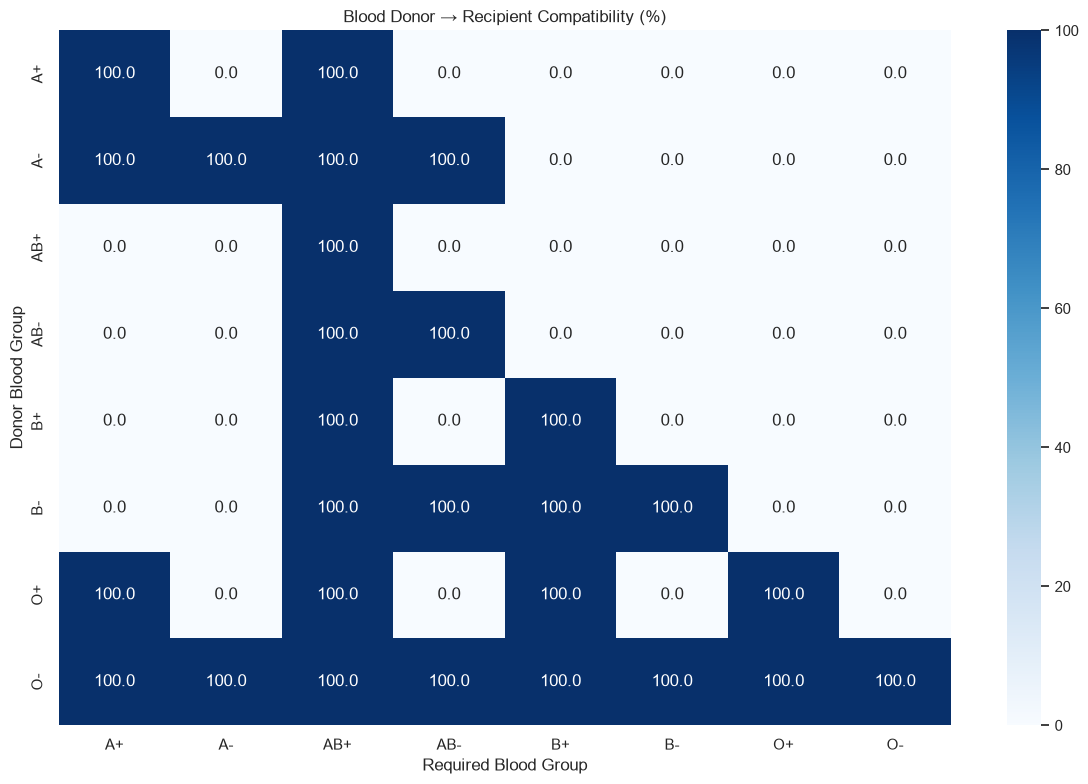

In [109]:
#Blood Compatibility Verification
compatibility_table = pd.crosstab(
    df["blood_group"],
    df["required_blood_group"],
    values=df["compatibility"],
    aggfunc="mean"
).fillna(0) * 100

plt.figure(figsize=(12, 8))

sns.heatmap(
    compatibility_table,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Blood Donor → Recipient Compatibility (%)")
plt.xlabel("Required Blood Group")
plt.ylabel("Donor Blood Group")

plt.tight_layout()
plt.show()

In [110]:
# ============================================
# MATCH SCORE CALCULATION
# ============================================

# Suggested weights:
#
# Compatibility   = 35%
# Availability    = 20%
# Distance        = 15%
# ETA             = 15%
# Response History = 15%
#
# Total = 100%

# ============================================
# RESPONSE SCORE
# ============================================

max_response = df["response_history"].max()

if max_response > 0:
    df["response_score"] = (
        df["response_history"]
        / max_response
    ).clip(0, 1)
else:
    df["response_score"] = 0.0

# ============================================
# MATCH SCORE
# ============================================

df["match_score_calculated"] = (

    0.35 * df["compatibility"]

    +

    0.20 * df["available"]

    +

    0.15 * df["distance_score"]

    +

    0.15 * df["eta_score"]

    +

    0.15 * df["response_score"]
)

# ============================================
# HARD ELIGIBILITY CONDITION
# ============================================

# Ineligible donors cannot be matched

df.loc[
    df["eligible"] == 0,
    "match_score_calculated"
] = 0

# ============================================
# HARD COMPATIBILITY CONDITION
# ============================================

# Incompatible donors cannot be matched

df.loc[
    df["compatibility"] == 0,
    "match_score_calculated"
] = 0

# ============================================
# ROUND FINAL SCORE
# ============================================

df["match_score_calculated"] = (
    df["match_score_calculated"]
    .clip(0, 1)
    .round(4)
)

# ============================================
# DISPLAY RESULTS
# ============================================

display(
    df[
        [
            "donor_id",
            "compatibility",
            "available",
            "distance_score",
            "eta_score",
            "response_score",
            "match_score_calculated"
        ]
    ].head(10)
)

,donor_id,compatibility,available,distance_score,eta_score,response_score,match_score_calculated
0,93246afe6c,1,0,0.795,0.797,0.00,0.5888
1,1b8b4c828a,0,0,0.821,0.821,0.35,0.0000
2,a6a3f7fe55,0,1,0.553,0.553,0.45,0.0000
3,cee6478144,0,1,0.776,0.772,0.45,0.0000
4,5986bc55f9,0,0,0.800,0.805,0.45,0.0000
5,486ffe4e4a,0,0,0.733,0.732,0.10,0.0000
6,32e4e74c30,0,1,0.837,0.837,0.85,0.0000
7,62927f7975,0,0,0.834,0.837,0.75,0.0000
8,17a47b3f43,0,0,0.894,0.894,0.65,0.0000
9,c6f6371120,0,1,0.994,0.959,1.00,0.0000


In [111]:
# ============================================
# DONOR RANKING
# ============================================

# Ranking is performed request-wise because
# the same donor can have different rankings
# for different blood requests.

df["donor_rank_calculated"] = (
    df.groupby("request_id")[
        "match_score_calculated"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

print("Request-wise donor ranking completed.")

display(
    df[
        [
            "request_id",
            "donor_id",
            "match_score_calculated",
            "donor_rank_calculated"
        ]
    ]
    .sort_values(
        [
            "request_id",
            "donor_rank_calculated"
        ]
    )
    .head(20)
)

Request-wise donor ranking completed.


,request_id,donor_id,match_score_calculated,donor_rank_calculated
0,1001,93246afe6c,0.5888,1
1,1001,1b8b4c828a,0.0000,2
2,1001,a6a3f7fe55,0.0000,3
3,1001,cee6478144,0.0000,4
4,1001,5986bc55f9,0.0000,5
5,1001,486ffe4e4a,0.0000,6
6,1001,32e4e74c30,0.0000,7
7,1001,62927f7975,0.0000,8
8,1001,17a47b3f43,0.0000,9
9,1001,c6f6371120,0.0000,10


In [112]:
# ============================================
# TOP-3 DONOR RECOMMENDATION
# ============================================

# Select only valid donors
top_donors = (
    df[
        (df["eligible"] == 1)
        &
        (df["available"] == 1)
        &
        (df["compatibility"] == 1)
    ]
    .sort_values(
        [
            "request_id",
            "match_score_calculated"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby("request_id")
    .head(3)
    .copy()
)

# Recalculate rank for valid donors only
top_donors["donor_rank_calculated"] = (
    top_donors
    .groupby("request_id")["match_score_calculated"]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

# Add recommendation label
top_donors["recommendation"] = "Recommended"

# ============================================
# DISPLAY TOP-3 DONORS
# ============================================

display(
    top_donors[
        [
            "request_id",
            "donor_id",
            "blood_group",
            "required_blood_group",
            "distance_km",
            "travel_time_min",
            "response_history",
            "match_score_calculated",
            "donor_rank_calculated",
            "recommendation"
        ]
    ]
    .sort_values(
        [
            "request_id",
            "donor_rank_calculated"
        ]
    )
    .head(30)
)

,request_id,donor_id,blood_group,required_blood_group,distance_km,travel_time_min,response_history,match_score_calculated,donor_rank_calculated,recommendation
10,1002,d3cf2f45e3,B-,B+,11.51,23,14,0.8988,1,Recommended
12,1002,f156dbaba5,B-,B+,14.25,28,14,0.8860,2,Recommended
13,1002,b38a588db1,B-,B+,19.42,39,8,0.8149,3,Recommended
30,1004,cd9e28dfdd,O+,O+,9.01,18,11,0.8886,1,Recommended
31,1004,e61bb198e6,O-,O+,24.15,48,1,0.7399,2,Recommended
40,1005,45494a599c,B+,B+,8.68,17,4,0.8380,1,Recommended
51,1006,1ab37e044c,O+,A+,18.74,37,13,0.8564,1,Recommended
50,1006,28275acb69,O+,A+,18.39,37,10,0.8348,2,Recommended
61,1007,30794b3812,A+,AB+,2.07,5,16,0.9588,1,Recommended
63,1007,57cb8819a9,A-,AB+,11.41,23,20,0.9440,2,Recommended


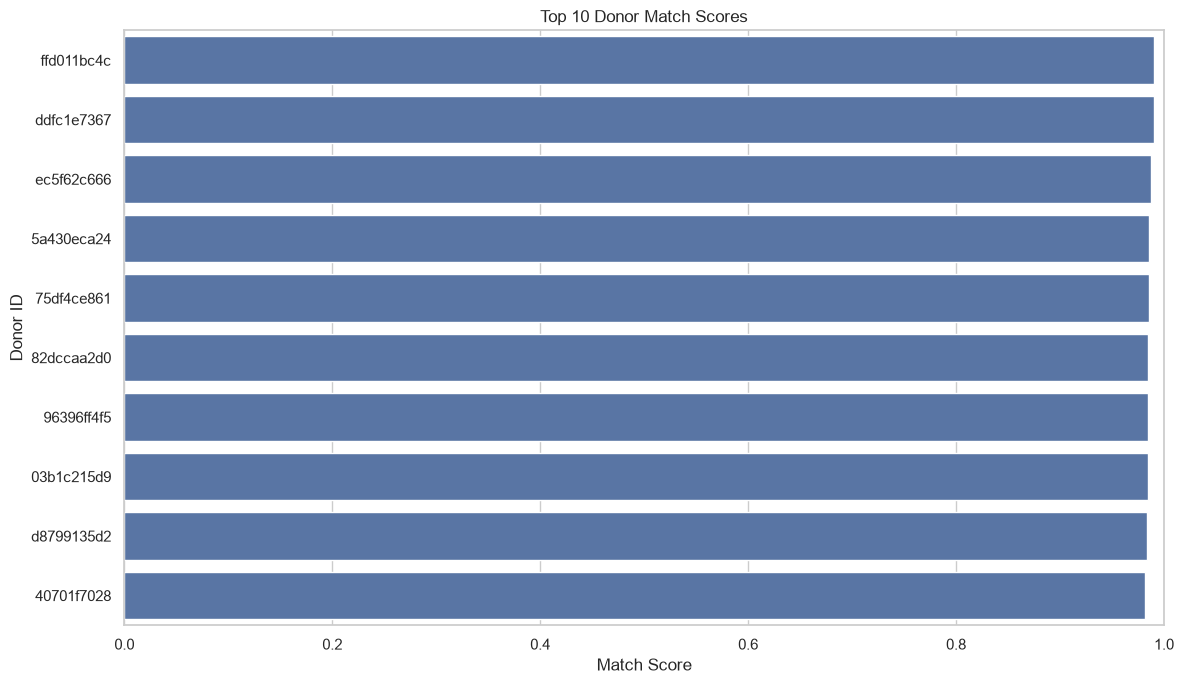

In [113]:
# ============================================
# TOP 10 DONOR MATCH SCORES
# ============================================

top_10_donors = (
    df[
        (df["eligible"] == 1)
        &
        (df["available"] == 1)
        &
        (df["compatibility"] == 1)
    ]
    .sort_values(
        "match_score_calculated",
        ascending=False
    )
    .head(10)
    .copy()
)

# ============================================
# PLOT
# ============================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_donors,
    y="donor_id",
    x="match_score_calculated"
)

plt.title(
    "Top 10 Donor Match Scores"
)

plt.xlabel(
    "Match Score"
)

plt.ylabel(
    "Donor ID"
)

plt.xlim(0, 1)

plt.tight_layout()

plt.show()

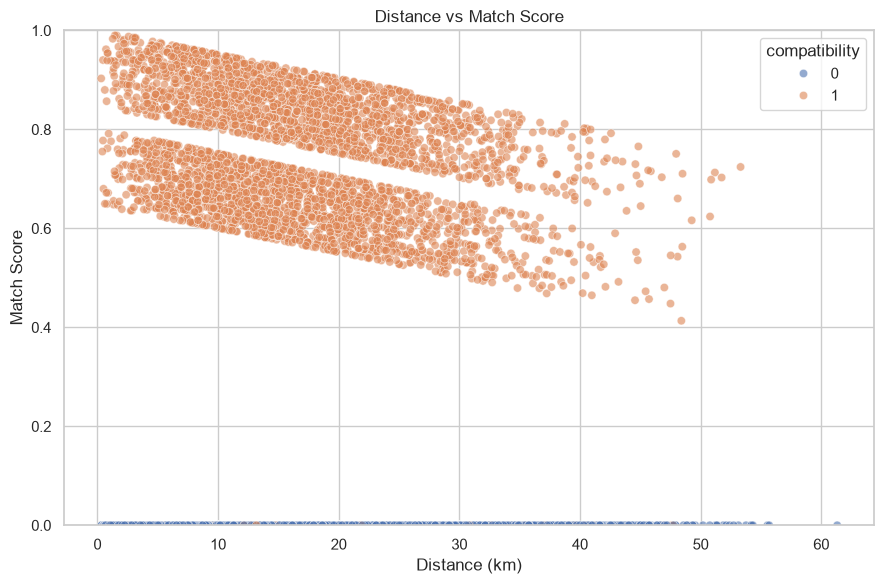

In [114]:
# ============================================
# DISTANCE VS MATCH SCORE
# ============================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="match_score_calculated",
    hue="compatibility",
    alpha=0.6
)

plt.title(
    "Distance vs Match Score"
)

plt.xlabel(
    "Distance (km)"
)

plt.ylabel(
    "Match Score"
)

plt.ylim(0, 1)

plt.tight_layout()

plt.show()

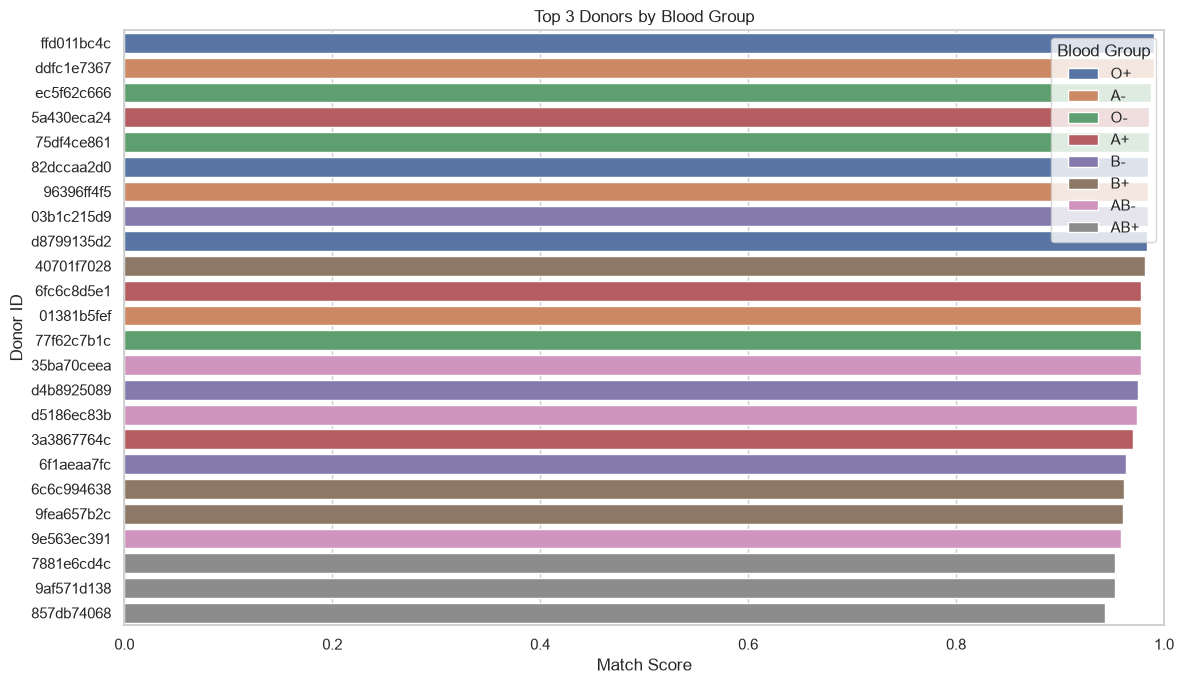

In [115]:
# ============================================
# TOP DONORS BY BLOOD GROUP
# ============================================

top_by_blood_group = (
    df[
        (df["eligible"] == 1)
        &
        (df["available"] == 1)
        &
        (df["compatibility"] == 1)
    ]
    .sort_values(
        "match_score_calculated",
        ascending=False
    )
    .groupby("blood_group")
    .head(3)
    .copy()
)

# ============================================
# PLOT
# ============================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_by_blood_group,
    x="match_score_calculated",
    y="donor_id",
    hue="blood_group"
)

plt.title(
    "Top 3 Donors by Blood Group"
)

plt.xlabel(
    "Match Score"
)

plt.ylabel(
    "Donor ID"
)

plt.xlim(0, 1)

plt.legend(
    title="Blood Group"
)

plt.tight_layout()

plt.show()

In [116]:
# ============================================
# FINAL MATCHING TABLE
# ============================================

final_matching_columns = [
    "donor_id",
    "request_id",
    "blood_group",
    "required_blood_group",
    "age",
    "gender",
    "donation_count",
    "last_donation_days",
    "eligible",
    "available",
    "distance_km",
    "travel_time_min",
    "compatibility",
    "response_history",
    "accepted_request",
    "distance_score",
    "eta_score",
    "response_score",
    "match_score_calculated",
    "donor_rank_calculated",
    "matched"
]

# Create final matching dataframe
final_matching_df = df[
    final_matching_columns
].copy()

# ============================================
# DISPLAY FINAL TABLE
# ============================================

print("=" * 70)
print("FINAL BLOOD DONOR MATCHING TABLE")
print("=" * 70)

print("\nTable Shape:")
print(final_matching_df.shape)

print("\nColumns:")
print(final_matching_df.columns.tolist())

print("\nPreview:")
display(
    final_matching_df.head(20)
)

FINAL BLOOD DONOR MATCHING TABLE

Table Shape:
(10000, 21)

Columns:
['donor_id', 'request_id', 'blood_group', 'required_blood_group', 'age', 'gender', 'donation_count', 'last_donation_days', 'eligible', 'available', 'distance_km', 'travel_time_min', 'compatibility', 'response_history', 'accepted_request', 'distance_score', 'eta_score', 'response_score', 'match_score_calculated', 'donor_rank_calculated', 'matched']

Preview:


,donor_id,request_id,blood_group,required_blood_group,age,gender,donation_count,last_donation_days,eligible,available,...,travel_time_min,compatibility,response_history,accepted_request,distance_score,eta_score,response_score,match_score_calculated,donor_rank_calculated,matched
0,93246afe6c,1001,O-,O+,18,Female,35,179,1,0,...,25,1,0,0,0.795,0.797,0.00,0.5888,1,0
1,1b8b4c828a,1001,A+,O+,27,Male,31,24,0,0,...,22,0,7,0,0.821,0.821,0.35,0.0000,2,0
2,a6a3f7fe55,1001,AB-,O+,45,Male,8,295,1,1,...,55,0,9,1,0.553,0.553,0.45,0.0000,3,0
3,cee6478144,1001,AB+,O+,54,Male,6,294,1,1,...,28,0,9,1,0.776,0.772,0.45,0.0000,4,0
4,5986bc55f9,1001,A-,O+,27,Female,20,43,0,0,...,24,0,9,1,0.800,0.805,0.45,0.0000,5,0
5,486ffe4e4a,1001,A+,O+,54,Female,21,132,1,0,...,33,0,2,1,0.733,0.732,0.10,0.0000,6,0
6,32e4e74c30,1001,B-,O+,49,Male,9,108,1,1,...,20,0,17,0,0.837,0.837,0.85,0.0000,7,0
7,62927f7975,1001,AB-,O+,29,Male,19,215,1,0,...,20,0,15,0,0.834,0.837,0.75,0.0000,8,0
8,17a47b3f43,1001,B-,O+,26,Female,5,145,1,0,...,13,0,13,1,0.894,0.894,0.65,0.0000,9,0
9,c6f6371120,1001,AB+,O+,30,Female,11,141,1,1,...,5,0,20,0,0.994,0.959,1.00,0.0000,10,0


In [117]:
# ============================================
# TOP 3 DONOR RECOMMENDATIONS
# ============================================

top_donors = (
    final_matching_df[
        (final_matching_df["eligible"] == 1)
        &
        (final_matching_df["available"] == 1)
        &
        (final_matching_df["compatibility"] == 1)
        &
        (final_matching_df["match_score_calculated"] > 0)
    ]
    .sort_values(
        ["request_id", "match_score_calculated"],
        ascending=[True, False]
    )
    .groupby("request_id")
    .head(3)
    .copy()
)

# Recalculate rank for the final recommendations
top_donors["recommendation_rank"] = (
    top_donors
    .groupby("request_id")["match_score_calculated"]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

top_donors["recommendation"] = "Recommended"

print("=" * 70)
print("TOP 3 BLOOD DONOR RECOMMENDATIONS")
print("=" * 70)

display(
    top_donors[
        [
            "request_id",
            "donor_id",
            "blood_group",
            "required_blood_group",
            "distance_km",
            "travel_time_min",
            "compatibility",
            "match_score_calculated",
            "recommendation_rank",
            "recommendation"
        ]
    ].head(30)
)

TOP 3 BLOOD DONOR RECOMMENDATIONS


,request_id,donor_id,blood_group,required_blood_group,distance_km,travel_time_min,compatibility,match_score_calculated,recommendation_rank,recommendation
10,1002,d3cf2f45e3,B-,B+,11.51,23,1,0.8988,1,Recommended
12,1002,f156dbaba5,B-,B+,14.25,28,1,0.8860,2,Recommended
13,1002,b38a588db1,B-,B+,19.42,39,1,0.8149,3,Recommended
30,1004,cd9e28dfdd,O+,O+,9.01,18,1,0.8886,1,Recommended
31,1004,e61bb198e6,O-,O+,24.15,48,1,0.7399,2,Recommended
40,1005,45494a599c,B+,B+,8.68,17,1,0.8380,1,Recommended
51,1006,1ab37e044c,O+,A+,18.74,37,1,0.8564,1,Recommended
50,1006,28275acb69,O+,A+,18.39,37,1,0.8348,2,Recommended
61,1007,30794b3812,A+,AB+,2.07,5,1,0.9588,1,Recommended
63,1007,57cb8819a9,A-,AB+,11.41,23,1,0.9440,2,Recommended


In [118]:
print("=" * 70)
print("FINAL MODEL SUMMARY")
print("=" * 70)

print("\nBest Classification Model:")
print(best_classifier_name)

best_classification_row = (
    classification_results_df[
        classification_results_df["Model"]
        == best_classifier_name
    ].iloc[0]
)

print(
    f"Accuracy  : {best_classification_row['Accuracy']:.4f}"
)

print(
    f"Precision : {best_classification_row['Precision']:.4f}"
)

print(
    f"Recall    : {best_classification_row['Recall']:.4f}"
)

print(
    f"F1 Score  : {best_classification_row['F1 Score']:.4f}"
)

print(
    f"ROC-AUC   : {best_classification_row['ROC-AUC']:.4f}"
)

print("\n" + "-" * 70)

print("\nBest Regression Model:")
print(best_regressor_name)

best_regression_row = (
    regression_results_df[
        regression_results_df["Model"]
        == best_regressor_name
    ].iloc[0]
)

print(
    f"MAE  : {best_regression_row['MAE']:.4f}"
)

print(
    f"RMSE : {best_regression_row['RMSE']:.4f}"
)

print(
    f"R²   : {best_regression_row['R2']:.4f}"
)

print("\n" + "=" * 70)

FINAL MODEL SUMMARY

Best Classification Model:
Logistic Regression
Accuracy  : 0.9780
Precision : 0.8932
Recall    : 0.9913
F1 Score  : 0.9397
ROC-AUC   : 0.9942

----------------------------------------------------------------------

Best Regression Model:
Random Forest
MAE  : 0.0111
RMSE : 0.1048
R²   : 1.0000



In [119]:
print("=" * 70)
print(" BLOOD DONOR MATCHING SYSTEM - PROJECT SUMMARY ")
print("=" * 70)

print(f"Total Records Processed      : {len(df):,}")
print(f"Total Unique Donors          : {df['donor_id'].nunique():,}")
print(f"Total Blood Requests         : {df['request_id'].nunique():,}")

print("-" * 70)

print(f"Eligible Donors             : {df['eligible'].sum():,}")
print(f"Available Donors            : {df['available'].sum():,}")
print(f"Matched Donor-Request Pairs : {df['matched'].sum():,}")

print("-" * 70)

print(f"Average Distance (km)       : {df['distance_km'].mean():.2f}")
print(f"Average Travel Time (min)   : {df['travel_time_min'].mean():.2f}")
print(f"Average Match Score         : {df['match_score_calculated'].mean():.2f}")

print("-" * 70)

print(f"Top Match Score             : {df['match_score_calculated'].max():.2f}")
print(f"Lowest Match Score          : {df['match_score_calculated'].min():.2f}")

print("=" * 70)
print("Blood Donor Matching System Completed Successfully")
print("=" * 70)

 BLOOD DONOR MATCHING SYSTEM - PROJECT SUMMARY 
Total Records Processed      : 10,000
Total Unique Donors          : 10,000
Total Blood Requests         : 1,000
----------------------------------------------------------------------
Eligible Donors             : 9,095
Available Donors            : 5,085
Matched Donor-Request Pairs : 1,728
----------------------------------------------------------------------
Average Distance (km)       : 17.10
Average Travel Time (min)   : 34.23
Average Match Score         : 0.30
----------------------------------------------------------------------
Top Match Score             : 0.99
Lowest Match Score          : 0.00
Blood Donor Matching System Completed Successfully
